# DSC8307 — Data Mining, Modelling and Analytics: Olist E-commerce Project

This notebook contains the full, reproducible analysis for the Advent 2026 project-based examination.
It answers five tasks on the Olist Brazilian e-commerce public dataset [1]:

1. Exploration and data preparation
2. Product categories frequently purchased together (association rules)
3. Seller segmentation by sales and service characteristics (clustering)
4. Unusual orders that merit operational review (anomaly detection)
5. Predicting (a) whether an order arrives late and (b) days from purchase to delivery

**How to run.** Install dependencies with `pip install -r requirements.txt` and run all cells from top to bottom.
The data ships with the repository (`data/brazilian-ecommerce.zip`, the unmodified Kaggle download [1]) and is
extracted automatically on first run.
A fixed random seed is used throughout. Figures are written to `figures/` and key tables to `outputs/`.

In [1]:
import os, warnings, json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

from mlxtend.frequent_patterns import apriori, association_rules
from sklearn.preprocessing import StandardScaler, RobustScaler
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.mixture import GaussianMixture
from sklearn.decomposition import PCA
from sklearn.metrics import (silhouette_score, davies_bouldin_score, adjusted_rand_score,
                             roc_auc_score, average_precision_score, brier_score_loss,
                             f1_score, precision_score, recall_score, mean_absolute_error,
                             mean_squared_error, r2_score, precision_recall_curve)
from sklearn.ensemble import IsolationForest
from sklearn.neighbors import LocalOutlierFactor
from sklearn.linear_model import LogisticRegression, Ridge
from sklearn.pipeline import make_pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.calibration import calibration_curve
from sklearn.model_selection import StratifiedKFold, KFold
import lightgbm as lgb

warnings.filterwarnings("ignore")
SEED = 42
np.random.seed(SEED)
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 160)
sns.set_theme(style="whitegrid", context="notebook")
DATA = Path("data")
# The Olist CSVs ship with this repository as data/brazilian-ecommerce.zip (CC BY-NC-SA 4.0, attribution: Olist [1]).
# Extract them on first run; if you downloaded the CSVs from Kaggle yourself, just place them in data/.
import zipfile
if not (DATA / "olist_orders_dataset.csv").exists():
    with zipfile.ZipFile(DATA / "brazilian-ecommerce.zip") as zf:
        for m in zf.namelist():
            if m.endswith(".csv") and "/" not in m and ".." not in m:
                zf.extract(m, DATA)
FIG = Path("figures"); FIG.mkdir(exist_ok=True)
OUT = Path("outputs"); OUT.mkdir(exist_ok=True)
RESULTS = {}  # key numbers collected for the report

def savefig(name):
    plt.tight_layout()
    plt.savefig(FIG / f"{name}.png", dpi=150, bbox_inches="tight")
    plt.show()

## Task 1 — Data exploration and preparation

### 1.1 Load the relational tables
The dataset is a relational snapshot of ~100k orders (Sep 2016 – Oct 2018) from the Olist marketplace, split across
nine tables linked by `order_id`, `customer_id`, `product_id`, `seller_id` and zip-code prefix.

In [2]:
files = {
    "customers": "olist_customers_dataset.csv",
    "geolocation": "olist_geolocation_dataset.csv",
    "items": "olist_order_items_dataset.csv",
    "payments": "olist_order_payments_dataset.csv",
    "reviews": "olist_order_reviews_dataset.csv",
    "orders": "olist_orders_dataset.csv",
    "products": "olist_products_dataset.csv",
    "sellers": "olist_sellers_dataset.csv",
    "translation": "product_category_name_translation.csv",
}
raw = {k: pd.read_csv(DATA / v) for k, v in files.items()}
overview = pd.DataFrame({
    "rows": {k: len(v) for k, v in raw.items()},
    "columns": {k: v.shape[1] for k, v in raw.items()},
    "cells_missing_%": {k: round(100 * v.isna().sum().sum() / v.size, 2) for k, v in raw.items()},
    "duplicate_rows": {k: int(v.duplicated().sum()) for k, v in raw.items()},
})
overview.to_csv(OUT / "table_overview.csv")
overview

,rows,columns,cells_missing_%,duplicate_rows
customers,99441,5,0.00,0
geolocation,1000163,5,0.00,261831
items,112650,7,0.00,0
payments,103886,5,0.00,0
reviews,99224,7,21.01,0
orders,99441,8,0.62,0
products,32951,9,0.83,0
sellers,3095,4,0.00,0
translation,71,2,0.00,0


### 1.2 Missingness, keys and integrity checks

In [3]:
for k, v in raw.items():
    m = v.isna().sum()
    m = m[m > 0]
    if len(m):
        print(f"{k}: {m.to_dict()}")

orders = raw["orders"].copy()
ts_cols = ["order_purchase_timestamp", "order_approved_at", "order_delivered_carrier_date",
           "order_delivered_customer_date", "order_estimated_delivery_date"]
for c in ts_cols:
    orders[c] = pd.to_datetime(orders[c])

print("\nOrder status distribution:")
print(orders["order_status"].value_counts())
print("\nPurchase date range:", orders.order_purchase_timestamp.min(), "->", orders.order_purchase_timestamp.max())

items = raw["items"].copy()
payments = raw["payments"].copy()
reviews = raw["reviews"].copy()
products = raw["products"].copy()
sellers = raw["sellers"].copy()
customers = raw["customers"].copy()

checks = {
    "orders_without_items": int((~orders.order_id.isin(items.order_id)).sum()),
    "orders_without_payment": int((~orders.order_id.isin(payments.order_id)).sum()),
    "orders_with_multiple_reviews": int(reviews.order_id.duplicated().sum()),
    "delivered_but_no_delivery_date": int(((orders.order_status == "delivered") & orders.order_delivered_customer_date.isna()).sum()),
    "carrier_pickup_before_approval": int((orders.order_delivered_carrier_date < orders.order_approved_at).sum()),
    "customer_delivery_before_carrier_pickup": int((orders.order_delivered_customer_date < orders.order_delivered_carrier_date).sum()),
    "products_missing_category": int(products.product_category_name.isna().sum()),
    "categories_without_translation": sorted(set(products.product_category_name.dropna()) - set(raw["translation"].product_category_name)),
    "customer_ids": int(customers.customer_id.nunique()),
    "unique_customers": int(customers.customer_unique_id.nunique()),
}
item_tot = items.groupby("order_id")[["price", "freight_value"]].sum().sum(axis=1)
pay_tot = payments.groupby("order_id").payment_value.sum()
gap = (pay_tot - item_tot).dropna()
checks["payment_vs_items_mismatch_gt_R$1"] = int((gap.abs() > 1).sum())
RESULTS["integrity"] = checks
checks

reviews: {'review_comment_title': 87656, 'review_comment_message': 58247}
orders: {'order_approved_at': 160, 'order_delivered_carrier_date': 1783, 'order_delivered_customer_date': 2965}
products: {'product_category_name': 610, 'product_name_lenght': 610, 'product_description_lenght': 610, 'product_photos_qty': 610, 'product_weight_g': 2, 'product_length_cm': 2, 'product_height_cm': 2, 'product_width_cm': 2}

Order status distribution:
order_status
delivered      96478
shipped         1107
canceled         625
unavailable      609
invoiced         314
processing       301
created            5
approved           2
Name: count, dtype: int64

Purchase date range: 2016-09-04 21:15:19 -> 2018-10-17 17:30:18


{'orders_without_items': 775,
 'orders_without_payment': 1,
 'orders_with_multiple_reviews': 551,
 'delivered_but_no_delivery_date': 8,
 'carrier_pickup_before_approval': 1359,
 'customer_delivery_before_carrier_pickup': 23,
 'products_missing_category': 610,
 'categories_without_translation': ['pc_gamer',
  'portateis_cozinha_e_preparadores_de_alimentos'],
 'customer_ids': 99441,
 'unique_customers': 96096,
 'payment_vs_items_mismatch_gt_R$1': 249}

**Comments.** The schema is clean in the sense of primary/foreign keys, but several issues matter for the tasks:

* `customer_id` is per-order; the true customer is `customer_unique_id` (99,441 ids vs 96,096 people), so repeat
  behaviour must be analysed on `customer_unique_id`.
* Missing delivery timestamps are almost all structural (orders that were cancelled, unavailable or still in transit),
  i.e. *missing not at random*; imputing them would fabricate outcomes, so they are excluded from delivery modelling.
* A small number of timestamp sequences are impossible (carrier pickup before approval, delivery before pickup) and some
  payments do not reconcile with item + freight totals. These are not silently dropped: they become signals for Task 4.
* 610 products have no category and two categories lack an English translation; we fill these explicitly.
* The review table has 551 orders with more than one review; we keep the latest review per order.

### 1.3 Distributions and temporal coverage

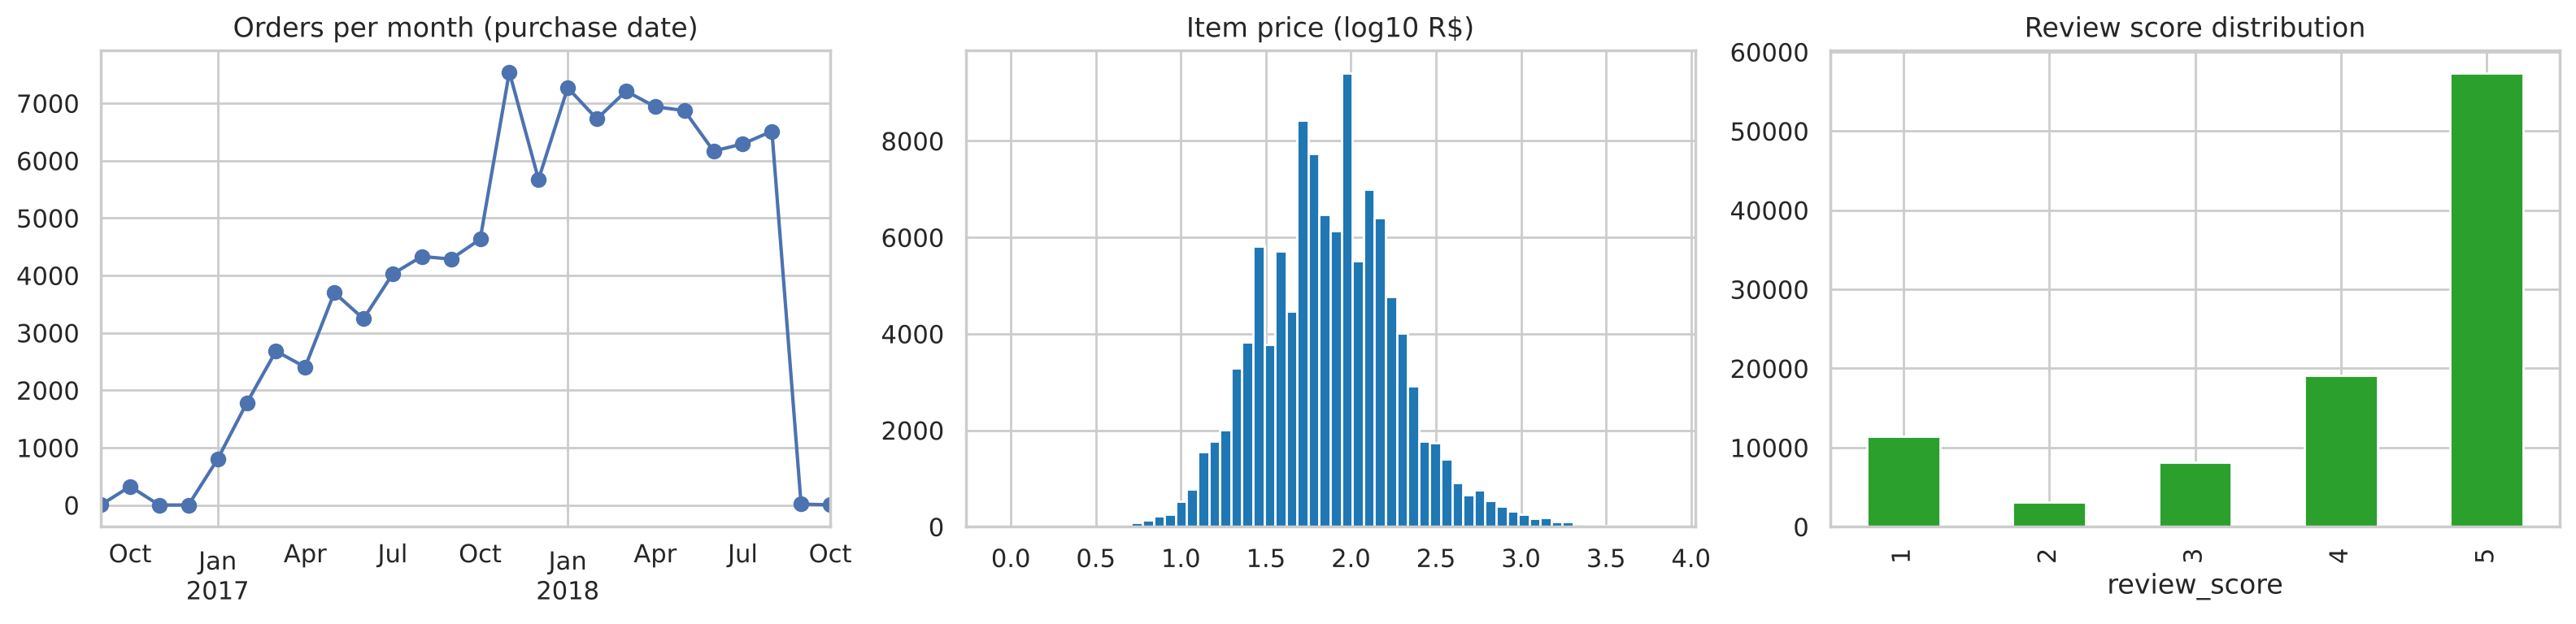

order_purchase_timestamp
2018-05-01    6873
2018-06-01    6167
2018-07-01    6292
2018-08-01    6512
2018-09-01      16
2018-10-01       4
Freq: MS, dtype: int64
           price  freight_value
count  112650.00      112650.00
mean      120.65          19.99
std       183.63          15.81
min         0.85           0.00
25%        39.90          13.08
50%        74.99          16.26
75%       134.90          21.15
max      6735.00         409.68


In [4]:
monthly = orders.set_index("order_purchase_timestamp").resample("MS").size()
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
monthly.plot(ax=ax[0], marker="o")
ax[0].set_title("Orders per month (purchase date)"); ax[0].set_xlabel("")
ax[1].hist(np.log10(items.price), bins=60, color="tab:blue")
ax[1].set_title("Item price (log10 R$)")
reviews.review_score.value_counts().sort_index().plot.bar(ax=ax[2], color="tab:green")
ax[2].set_title("Review score distribution")
savefig("fig1_eda_overview")
print(monthly.tail(6))
print(items[["price", "freight_value"]].describe().round(2))

Volume grows rapidly through 2017, peaks with Black Friday (Nov 2017) and then plateaus. Sep 2016 – Dec 2016 and
Sep – Oct 2018 contain only a handful of orders, i.e. they are partial/edge months. Prices are strongly right-skewed
(median ≈ R$75, max R$6,735), so log transforms are used where distance-based methods are applied. Reviews are
J-shaped (58% five stars, 11.5% one star), typical of e-commerce ratings.

### 1.4 Data preparation

Steps and justification:

1. **Timestamps parsed** to datetimes; durations derived in fractional days.
2. **Categories**: missing → `unknown`; untranslated Portuguese names mapped manually; English names used throughout.
3. **Geolocation**: the raw table has ~1M rows with several coordinates per zip prefix and some points outside Brazil.
   We keep points inside Brazil's bounding box and take the **median** lat/lng per prefix (robust to stray points),
   then compute great-circle (haversine) seller→customer distance.
4. **Reviews**: keep the latest review per order.
5. **Order-level table**: aggregate items (count, value, freight, weight, volume, number of sellers/categories) and
   payments (total, instalments, main type) to one row per order.
6. **Delivery outcome**: for delivered orders with a delivery timestamp, `delivery_days` = delivered − purchased and
   `late` = delivered *date* after the estimated delivery *date* (the estimate is a date, so delivery on that day is on time).
7. **Edge months** (before 2017-01 and after 2018-08) are excluded from modelling because they are sparse and
   right-censored (late orders bought in Sep/Oct 2018 had not yet been delivered when the snapshot was taken).

In [5]:
trans = dict(zip(raw["translation"].product_category_name, raw["translation"].product_category_name_english))
trans.update({"pc_gamer": "pc_gamer", "portateis_cozinha_e_preparadores_de_alimentos": "portable_kitchen_food_processors"})
products["category"] = products.product_category_name.map(trans).fillna("unknown")
products["volume_cm3"] = products.product_length_cm * products.product_height_cm * products.product_width_cm

geo = raw["geolocation"]
geo = geo[geo.geolocation_lat.between(-34, 5.5) & geo.geolocation_lng.between(-74, -34)]
geo_zip = geo.groupby("geolocation_zip_code_prefix")[["geolocation_lat", "geolocation_lng"]].median()
print("Zip prefixes with coordinates:", len(geo_zip))

def haversine(lat1, lon1, lat2, lon2):
    lat1, lon1, lat2, lon2 = map(np.radians, [lat1, lon1, lat2, lon2])
    a = np.sin((lat2 - lat1) / 2) ** 2 + np.cos(lat1) * np.cos(lat2) * np.sin((lon2 - lon1) / 2) ** 2
    return 6371 * 2 * np.arcsin(np.sqrt(a))

customers = customers.join(geo_zip, on="customer_zip_code_prefix").rename(columns={"geolocation_lat": "c_lat", "geolocation_lng": "c_lng"})
sellers = sellers.join(geo_zip, on="seller_zip_code_prefix").rename(columns={"geolocation_lat": "s_lat", "geolocation_lng": "s_lng"})

reviews["review_answer_timestamp"] = pd.to_datetime(reviews["review_answer_timestamp"])
reviews_l = reviews.sort_values("review_answer_timestamp").drop_duplicates("order_id", keep="last")

# item level enriched
it = (items.merge(products[["product_id", "category", "product_weight_g", "volume_cm3", "product_photos_qty",
                            "product_description_lenght"]], on="product_id", how="left")
           .merge(sellers[["seller_id", "seller_state", "s_lat", "s_lng"]], on="seller_id", how="left"))
it["item_value"] = it.price + it.freight_value

# main seller per order = seller with largest value share
main_seller = (it.groupby(["order_id", "seller_id"]).item_value.sum().reset_index()
                 .sort_values("item_value", ascending=False).drop_duplicates("order_id")[["order_id", "seller_id"]])

ord_items = it.groupby("order_id").agg(
    n_items=("order_item_id", "size"), n_products=("product_id", "nunique"), n_sellers=("seller_id", "nunique"),
    n_categories=("category", "nunique"), items_price=("price", "sum"), freight=("freight_value", "sum"),
    max_price=("price", "max"), weight_g=("product_weight_g", "sum"), volume_cm3=("volume_cm3", "sum"),
    photos=("product_photos_qty", "mean"), desc_len=("product_description_lenght", "mean"),
    main_category=("category", lambda s: s.value_counts().index[0]),
    shipping_limit=("shipping_limit_date", "max"),
).reset_index()
ord_items["shipping_limit"] = pd.to_datetime(ord_items["shipping_limit"])

pay = payments.groupby("order_id").agg(
    pay_total=("payment_value", "sum"), installments=("payment_installments", "max"),
    n_payment_methods=("payment_type", "nunique"), n_payment_rows=("payment_sequential", "max"),
    pay_type=("payment_type", lambda s: s.value_counts().index[0])).reset_index()

df = (orders.merge(customers, on="customer_id", how="left")
            .merge(ord_items, on="order_id", how="left")
            .merge(main_seller, on="order_id", how="left")
            .merge(sellers[["seller_id", "seller_state", "s_lat", "s_lng"]], on="seller_id", how="left")
            .merge(pay, on="order_id", how="left")
            .merge(reviews_l[["order_id", "review_score"]], on="order_id", how="left"))
df["distance_km"] = haversine(df.s_lat, df.s_lng, df.c_lat, df.c_lng)
df["same_state"] = (df.seller_state == df.customer_state).astype(float)
df["order_value"] = df.items_price + df.freight
df["freight_ratio"] = df.freight / df.order_value
df["pay_gap"] = df.pay_total - df.order_value
d = lambda a, b: (df[a] - df[b]).dt.total_seconds() / 86400
df["approval_hours"] = d("order_approved_at", "order_purchase_timestamp") * 24
df["handling_days"] = d("order_delivered_carrier_date", "order_approved_at")
df["transit_days"] = d("order_delivered_customer_date", "order_delivered_carrier_date")
df["delivery_days"] = d("order_delivered_customer_date", "order_purchase_timestamp")
df["promised_days"] = d("order_estimated_delivery_date", "order_purchase_timestamp")
df["late"] = (df.order_delivered_customer_date.dt.normalize() > df.order_estimated_delivery_date).astype(int)
df["days_late"] = (df.order_delivered_customer_date.dt.normalize() - df.order_estimated_delivery_date).dt.days
df["purchase_month"] = df.order_purchase_timestamp.dt.to_period("M")
df.loc[df.order_delivered_customer_date.isna(), ["late", "days_late"]] = np.nan
print(df.shape)
df.head(3)

Zip prefixes with coordinates: 19010


(99441, 50)


,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state,c_lat,c_lng,n_items,n_products,n_sellers,n_categories,items_price,freight,max_price,weight_g,volume_cm3,photos,desc_len,main_category,shipping_limit,seller_id,seller_state,s_lat,s_lng,pay_total,installments,n_payment_methods,n_payment_rows,pay_type,review_score,distance_km,same_state,order_value,freight_ratio,pay_gap,approval_hours,handling_days,transit_days,delivery_days,promised_days,late,days_late,purchase_month
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18,7c396fd4830fd04220f754e42b4e5bff,3149,sao paulo,SP,-23.576170,-46.587276,1.0,1.0,1.0,1.0,29.99,8.72,29.99,500.0,1976.0,4.0,268.0,housewares,2017-10-06 11:07:15,3504c0cb71d7fa48d967e0e4c94d59d9,SP,-23.681180,-46.444127,38.71,1.0,2.0,3.0,voucher,4.0,18.681711,1.0,38.71,0.225265,0.0,0.178333,2.366493,6.062650,8.436574,15.544063,0.0,-8.0,2017-10
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13,af07308b275d755c9edb36a90c618231,47813,barreiras,BA,-12.126651,-45.008162,1.0,1.0,1.0,1.0,118.70,22.76,118.70,400.0,4693.0,1.0,178.0,perfumery,2018-07-30 03:24:27,289cdb325fb7e7f891c38608bf9e0962,SP,-19.807013,-43.980966,141.46,1.0,1.0,1.0,boleto,4.0,861.035367,0.0,141.46,0.160894,0.0,30.713889,0.462882,12.039410,13.782037,19.137766,0.0,-6.0,2018-07
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04,3a653a41f6f9fc3d2a113cf8398680e8,75265,vianopolis,GO,-16.744472,-48.514624,1.0,1.0,1.0,1.0,159.90,19.22,159.90,420.0,9576.0,1.0,232.0,auto,2018-08-13 08:55:23,4869f7a5dfa277a7dca6462dcf3b52b2,SP,-21.364020,-48.228831,179.12,3.0,1.0,1.0,credit_card,5.0,514.547140,0.0,179.12,0.107302,0.0,0.276111,0.204595,9.178113,9.394213,26.639711,0.0,-18.0,2018-08


### 1.5 Preliminary delivery analysis (motivates Task 5)

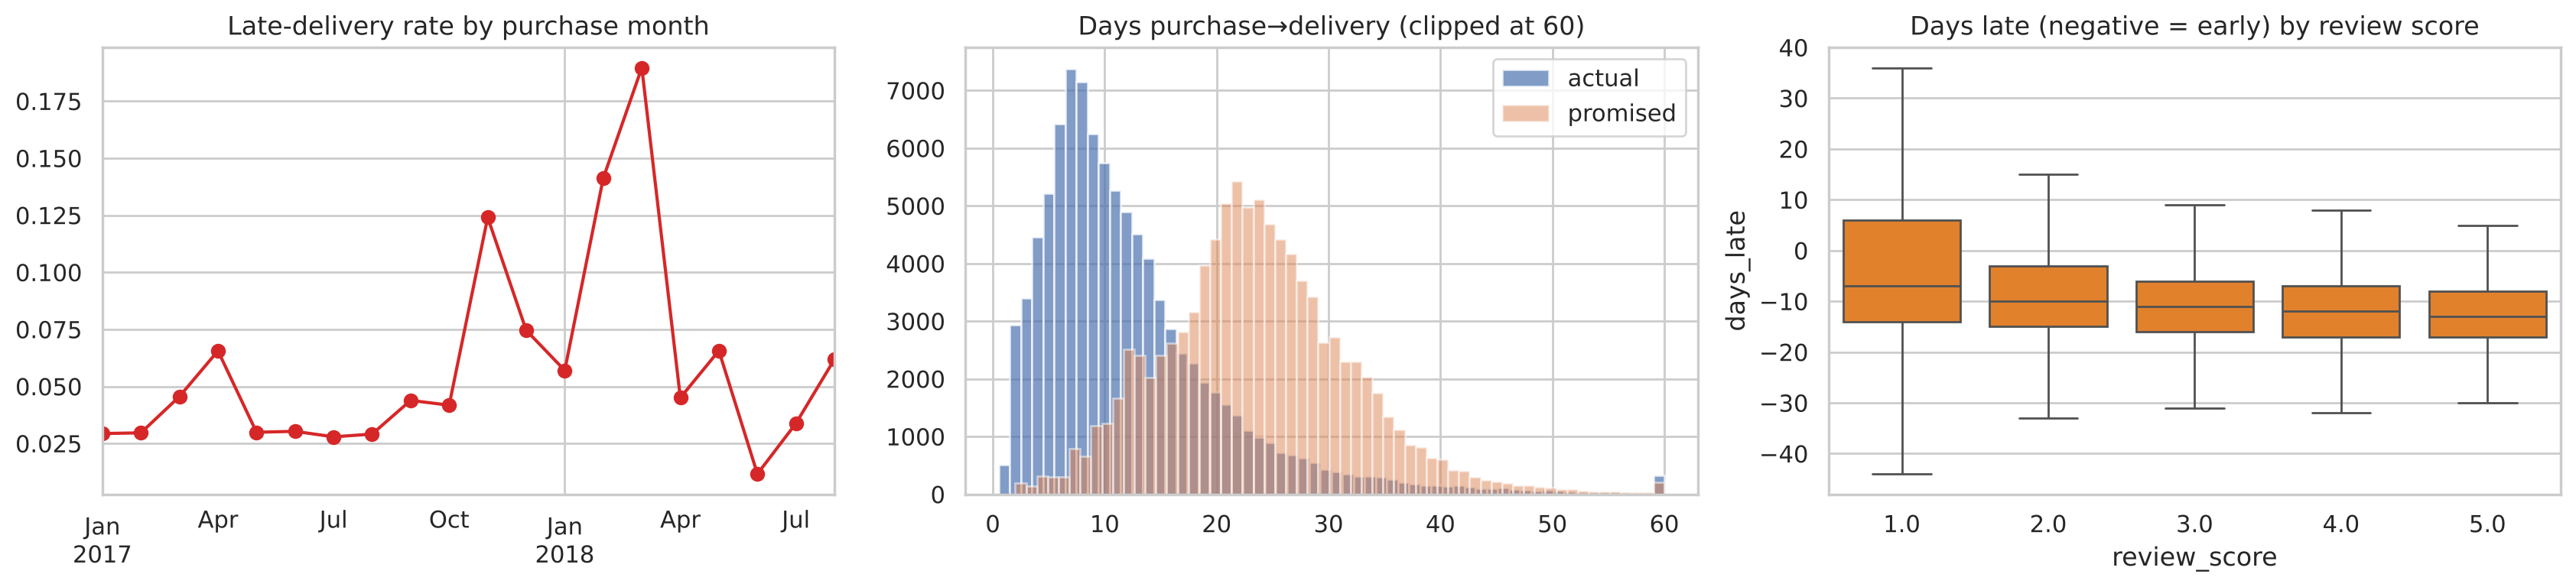

Late rate overall: 0.0679
                late_rate      n  median_days
customer_state                               
AL                  0.215    396       22.329
MA                  0.175    713       19.183
SE                  0.154    332       17.928
PI                  0.139    475       16.279
CE                  0.138   1273       18.171
RR                  0.125     40       25.131
BA                  0.122   3253       16.913
RJ                  0.121  12310       12.036
Mean review | on time vs late: {0.0: 4.29, 1.0: 2.27}


In [6]:
dl = df[(df.order_status == "delivered") & df.delivery_days.notna()].copy()
in_window = (dl.order_purchase_timestamp >= "2017-01-01") & (dl.order_purchase_timestamp < "2018-09-01")
dl = dl[in_window]
RESULTS["delivered_orders_modelling_window"] = len(dl)
RESULTS["late_rate_overall"] = round(dl.late.mean(), 4)
RESULTS["delivery_days_median"] = round(dl.delivery_days.median(), 2)
RESULTS["delivery_days_mean"] = round(dl.delivery_days.mean(), 2)
RESULTS["promised_days_median"] = round(dl.promised_days.median(), 2)
late_by_month = dl.groupby("purchase_month").late.mean()
late_by_state = dl.groupby("customer_state").agg(late_rate=("late", "mean"), n=("late", "size"), median_days=("delivery_days", "median")).sort_values("late_rate", ascending=False)

fig, ax = plt.subplots(1, 3, figsize=(17, 4))
late_by_month.plot(ax=ax[0], marker="o", color="tab:red"); ax[0].set_title("Late-delivery rate by purchase month"); ax[0].set_xlabel("")
ax[1].hist(dl.delivery_days.clip(upper=60), bins=60, alpha=.7, label="actual")
ax[1].hist(dl.promised_days.clip(upper=60), bins=60, alpha=.5, label="promised")
ax[1].legend(); ax[1].set_title("Days purchase→delivery (clipped at 60)")
sns.boxplot(data=dl, x="review_score", y="days_late", ax=ax[2], showfliers=False, color="tab:orange")
ax[2].set_title("Days late (negative = early) by review score")
savefig("fig2_delivery_eda")
print("Late rate overall:", RESULTS["late_rate_overall"])
print(late_by_state.head(8).round(3))
rv = dl.dropna(subset=["review_score"])
print("Mean review | on time vs late:", rv.groupby("late").review_score.mean().round(2).to_dict())
RESULTS["review_ontime_vs_late"] = rv.groupby("late").review_score.mean().round(2).to_dict()
RESULTS["late_by_month_max"] = (str(late_by_month.idxmax()), round(late_by_month.max(), 3))
RESULTS["late_by_state_top"] = late_by_state.head(5).round(3).reset_index().to_dict("records")

**Comments.** About 6.8% of delivered orders arrive after the promised date, but this is highly non-stationary:
late rates spike in Nov 2017 (Black Friday, 12%) and Feb–Mar 2018 (14–19%), and fall to 1–3% in quiet months.
Olist's estimates are deliberately conservative (median promise ≈ 23 days vs median actual ≈ 10 days). Lateness
is strongly associated with poor reviews (mean score ≈ 4.3 on time vs ≈ 2.3 late), which makes delivery
reliability commercially important. Northern/north-eastern states (e.g. AL, MA) are far more often late than SP.
These observations imply: (i) a **time-based** train/test split is required to obtain honest estimates, (ii) the
promised lead time and geography should be strong predictors, and (iii) class imbalance must be handled through
appropriate metrics (PR-AUC) rather than accuracy.

## Task 2 — Product categories frequently purchased together

**Method.** Market-basket analysis with the Apriori algorithm [2] and association rules scored by support,
confidence and lift [3]. Every rule is also tested with a one-sided Fisher exact test (H1: lift > 1) with a
Benjamini–Hochberg (BH) false-discovery-rate correction, because with small supports a high lift can arise by chance.
Analysis proceeds in three steps:

1. **Population view** — how often do orders/customers span more than one category, and are pairs of categories
   over-represented relative to independence across *all* orders?
2. **Conditional order baskets** — among orders containing ≥2 categories, which categories go together?
3. **Conditional customer baskets** — among customers (`customer_unique_id`) who bought ≥2 categories over their
   lifetime, which categories go together (cross-sell over time)?

In [7]:
import itertools
order_cats = it.groupby("order_id").category.apply(lambda s: sorted(set(s)))
n_cat = order_cats.apply(len)
cust_map = orders.merge(customers[["customer_id", "customer_unique_id"]], on="customer_id")[["order_id", "customer_unique_id"]]
cust_cats = it.merge(cust_map, on="order_id").groupby("customer_unique_id").category.apply(lambda s: sorted(set(s)))
RESULTS["orders_multi_category"] = int((n_cat > 1).sum())
RESULTS["orders_multi_category_pct"] = round(100 * (n_cat > 1).mean(), 2)
RESULTS["customers_multi_category"] = int((cust_cats.apply(len) > 1).sum())
RESULTS["customers_multi_category_pct"] = round(100 * (cust_cats.apply(len) > 1).mean(), 2)
multi_orders = order_cats[n_cat > 1].index
sellers_per_multi = it[it.order_id.isin(multi_orders)].groupby("order_id").seller_id.nunique()
RESULTS["multi_cat_orders_multi_seller_pct"] = round(100 * (sellers_per_multi > 1).mean(), 1)
print(f"Orders with >1 category: {RESULTS['orders_multi_category']} ({RESULTS['orders_multi_category_pct']}%)")
print(f"Customers with >1 category (lifetime): {RESULTS['customers_multi_category']} ({RESULTS['customers_multi_category_pct']}%)")
print(f"Multi-category orders fulfilled by >1 seller: {RESULTS['multi_cat_orders_multi_seller_pct']}%")

# Population-level pair lift across ALL orders
N = len(order_cats)
cnt = pd.Series([c for b in order_cats for c in b]).value_counts()
pairs = pd.Series([p for b in order_cats for p in itertools.combinations(b, 2)]).value_counts()
pop = pd.DataFrame({"pair": [" + ".join(p) for p in pairs.index], "co_orders": pairs.values,
                    "lift_all_orders": [c * N / (cnt[a] * cnt[b]) for (a, b), c in zip(pairs.index, pairs.values)]})
RESULTS["pop_pairs_lift_gt1_among_top20"] = int((pop.head(20).lift_all_orders > 1).sum())
pop.head(15).round(3)

Orders with >1 category: 786 (0.8%)
Customers with >1 category (lifetime): 2327 (2.44%)
Multi-category orders fulfilled by >1 seller: 76.0%


,pair,co_orders,lift_all_orders
0,bed_bath_table + furniture_decor,70,0.114
1,bed_bath_table + home_confort,43,1.135
2,furniture_decor + housewares,24,0.062
3,bed_bath_table + housewares,20,0.036
4,baby + cool_stuff,20,0.188
5,baby + toys,19,0.167
6,furniture_decor + garden_tools,17,0.074
7,baby + bed_bath_table,17,0.062
8,housewares + unknown,14,0.162
9,health_beauty + sports_leisure,14,0.020


**Comment.** Fewer than 1% of orders span two categories and, across *all* orders, nearly every category pair has
lift < 1: buying from one category makes a second category in the *same order* less likely than chance, simply because
almost every order is single-category. A naive site-wide Apriori therefore finds essentially no rules. The commercially
useful question is conditional: *when* a customer does buy across categories, which combinations occur? We answer this
on the multi-category baskets, and on customer lifetime baskets.

In [8]:
def mine(baskets, min_count, label):
    cats = sorted({c for b in baskets for c in b})
    onehot = pd.DataFrame([[c in set(b) for c in cats] for b in baskets], columns=cats)
    Nb = len(onehot)
    fi = apriori(onehot, min_support=min_count / Nb, use_colnames=True, max_len=2)
    rules = association_rules(fi, metric="lift", min_threshold=0.0)
    pvals = []
    for _, r in rules.iterrows():
        a = onehot[list(r.antecedents)].all(axis=1); c = onehot[list(r.consequents)].all(axis=1)
        tab = [[(a & c).sum(), (a & ~c).sum()], [(~a & c).sum(), (~a & ~c).sum()]]
        pvals.append(stats.fisher_exact(tab, alternative="greater")[1])
    pvals = np.array(pvals)
    if len(pvals):
        order_ = np.argsort(pvals); m = len(pvals)
        q = np.empty(m); q[order_] = np.minimum.accumulate((pvals[order_] * m / np.arange(1, m + 1))[::-1])[::-1]
    else:
        q = pvals
    rules["p_value"] = pvals; rules["q_value_BH"] = np.minimum(q, 1)
    rules["co_count"] = (rules.support * Nb).round().astype(int)
    rules["antecedents"] = rules.antecedents.apply(lambda s: ", ".join(sorted(s)))
    rules["consequents"] = rules.consequents.apply(lambda s: ", ".join(sorted(s)))
    rules["level"] = label; rules["n_baskets"] = Nb
    return rules[["level", "n_baskets", "antecedents", "consequents", "co_count", "support", "confidence", "lift", "p_value", "q_value_BH"]].sort_values("lift", ascending=False)

order_multi = order_cats[n_cat > 1].tolist()
cust_multi = cust_cats[cust_cats.apply(len) > 1].tolist()
MIN_COUNT = 5
r_order = mine(order_multi, MIN_COUNT, "order (multi-category)")
r_cust = mine(cust_multi, MIN_COUNT, "customer (multi-category)")
rules_all = pd.concat([r_order, r_cust])
rules_all.to_csv(OUT / "association_rules_all.csv", index=False)
rules_sig = rules_all[(rules_all.q_value_BH < 0.05) & (rules_all.lift > 1)].copy()
RESULTS["assoc_n_rules"] = {"order": len(r_order), "customer": len(r_cust), "significant": len(rules_sig)}
print(RESULTS["assoc_n_rules"])
rules_sig.round(4)

{'order': 82, 'customer': 294, 'significant': 52}


,level,n_baskets,antecedents,consequents,co_count,support,confidence,lift,p_value,q_value_BH
3,order (multi-category),786,audio,watches_gifts,6,0.0076,1.0000,19.6500,0.0000,0.0000
2,order (multi-category),786,watches_gifts,audio,6,0.0076,0.1500,19.6500,0.0000,0.0000
73,order (multi-category),786,luggage_accessories,stationery,5,0.0064,0.3333,7.9394,0.0002,0.0012
72,order (multi-category),786,stationery,luggage_accessories,5,0.0064,0.1515,7.9394,0.0002,0.0012
47,order (multi-category),786,unknown,fashion_bags_accessories,9,0.0115,0.1452,5.7048,0.0000,0.0000
46,order (multi-category),786,fashion_bags_accessories,unknown,9,0.0115,0.4500,5.7048,0.0000,0.0000
74,order (multi-category),786,unknown,pet_shop,6,0.0076,0.0968,5.0710,0.0005,0.0028
75,order (multi-category),786,pet_shop,unknown,6,0.0076,0.4000,5.0710,0.0005,0.0028
65,order (multi-category),786,health_beauty,perfumery,12,0.0153,0.1667,4.6786,0.0000,0.0000
64,order (multi-category),786,perfumery,health_beauty,12,0.0153,0.4286,4.6786,0.0000,0.0000


### 2.1 Sensitivity to the minimum-count threshold
Re-mined with minimum co-occurrence counts of 3, 5 and 10 baskets; we check whether the significant pairs persist.

In [9]:
sens = []
for mc in [3, 5, 10]:
    for lvl, b in [("order", order_multi), ("customer", cust_multi)]:
        r = mine(b, mc, lvl)
        r = r[(r.q_value_BH < 0.05) & (r.lift > 1)]
        pairs_ = sorted({" + ".join(sorted([a, c])) for a, c in zip(r.antecedents, r.consequents)})
        sens.append({"min_count": mc, "level": lvl, "n_sig_pairs": len(pairs_), "pairs": "; ".join(pairs_)})
sens = pd.DataFrame(sens)
RESULTS["assoc_sensitivity"] = sens.to_dict("records")
sens

,min_count,level,n_sig_pairs,pairs
0,3,order,17,art + furniture_decor; audio + watches_gifts; ...
1,3,customer,7,audio + watches_gifts; baby + cool_stuff; baby...
2,5,order,19,art + furniture_decor; audio + watches_gifts; ...
3,5,customer,7,audio + watches_gifts; baby + cool_stuff; baby...
4,10,order,8,baby + cool_stuff; baby + toys; bed_bath_table...
5,10,customer,5,baby + cool_stuff; baby + toys; bed_bath_table...


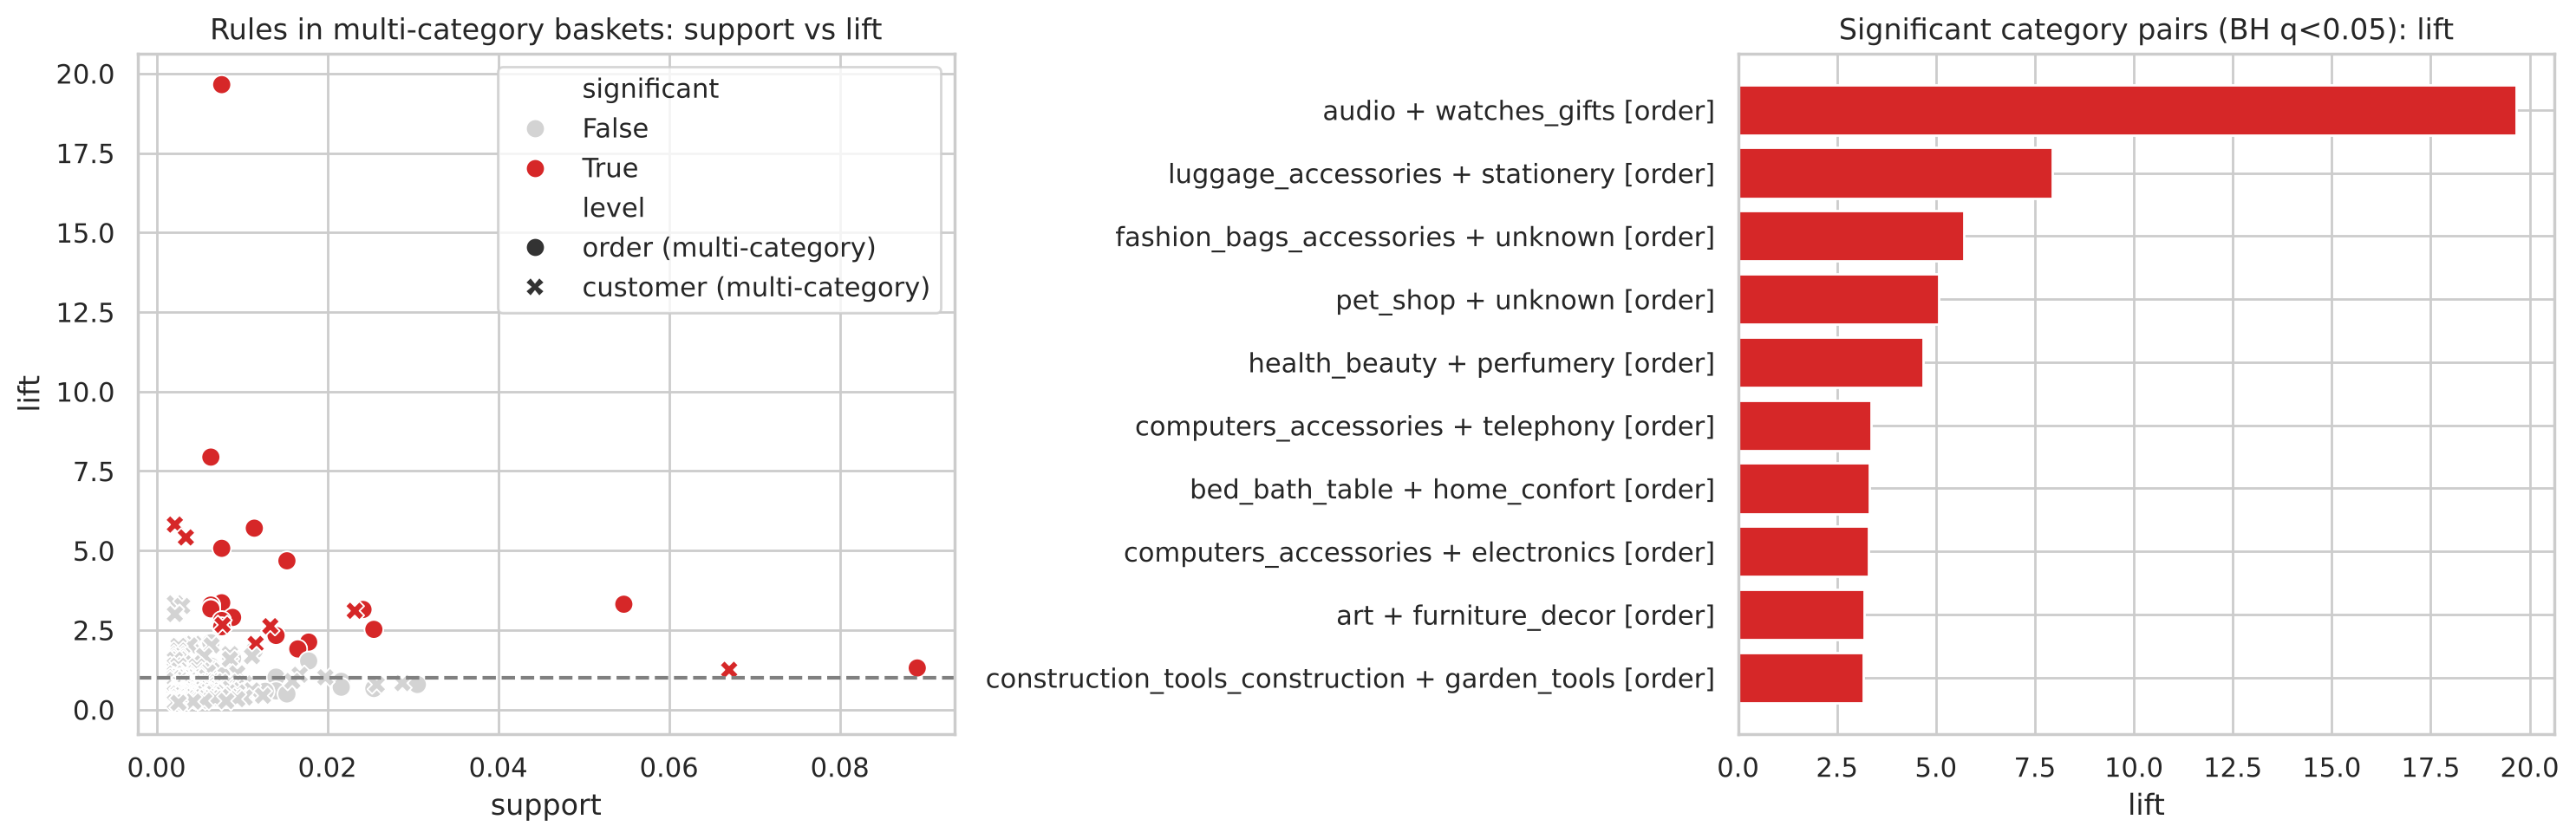

,level,n_baskets,antecedents,consequents,co_count,support,confidence,lift,p_value,q_value_BH,pair
3,order (multi-category),786,audio,watches_gifts,6,0.0076,1.0000,19.6500,0.0000,0.0000,audio + watches_gifts
73,order (multi-category),786,luggage_accessories,stationery,5,0.0064,0.3333,7.9394,0.0002,0.0012,luggage_accessories + stationery
46,order (multi-category),786,fashion_bags_accessories,unknown,9,0.0115,0.4500,5.7048,0.0000,0.0000,fashion_bags_accessories + unknown
75,order (multi-category),786,pet_shop,unknown,6,0.0076,0.4000,5.0710,0.0005,0.0028,pet_shop + unknown
64,order (multi-category),786,perfumery,health_beauty,12,0.0153,0.4286,4.6786,0.0000,0.0000,health_beauty + perfumery
37,order (multi-category),786,telephony,computers_accessories,6,0.0076,0.2222,3.3590,0.0063,0.0193,computers_accessories + telephony
22,order (multi-category),786,home_confort,bed_bath_table,43,0.0547,0.8600,3.3135,0.0000,0.0000,bed_bath_table + home_confort
33,order (multi-category),786,electronics,computers_accessories,5,0.0064,0.2174,3.2860,0.0141,0.0360,computers_accessories + electronics
1,order (multi-category),786,art,furniture_decor,5,0.0064,0.8333,3.1796,0.0056,0.0192,art + furniture_decor
39,order (multi-category),786,construction_tools_construction,garden_tools,5,0.0064,0.2941,3.1668,0.0154,0.0360,construction_tools_construction + garden_tools


In [10]:
top = rules_sig.copy()
top["pair"] = top.apply(lambda r: " + ".join(sorted([r.antecedents, r.consequents])), axis=1)
top_pairs = top.sort_values("confidence", ascending=False).drop_duplicates(["level", "pair"]).sort_values(["level", "lift"], ascending=[False, False])
plot_df = rules_all[rules_all.lift > 0].copy(); plot_df["significant"] = (plot_df.q_value_BH < 0.05) & (plot_df.lift > 1)
fig, ax = plt.subplots(1, 2, figsize=(15, 5))
sns.scatterplot(data=plot_df, x="support", y="lift", hue="significant", style="level", s=60, ax=ax[0], palette={True: "tab:red", False: "lightgrey"})
ax[0].axhline(1, ls="--", c="grey"); ax[0].set_title("Rules in multi-category baskets: support vs lift")
lab = top_pairs.drop_duplicates("pair").head(10)
ax[1].barh(lab.pair + " [" + lab.level.str.split(" ").str[0] + "]", lab.lift, color="tab:red"); ax[1].invert_yaxis()
ax[1].set_title("Significant category pairs (BH q<0.05): lift"); ax[1].set_xlabel("lift")
savefig("fig3_association_rules")
top_pairs.round(4).to_csv(OUT / "association_top_pairs.csv", index=False)
RESULTS["assoc_top_pairs"] = top_pairs[["level", "antecedents", "consequents", "co_count", "support", "confidence", "lift", "q_value_BH"]].round(4).to_dict("records")
top_pairs.round(4)

**Interpretation.** Within cross-category baskets, the significant associations form coherent *missions*: a home
furnishing cluster (bed_bath_table, home_confort, furniture_decor, housewares, garden_tools, home_construction)
and a children's cluster (baby, toys, cool_stuff). Because ~3 in 4 multi-category orders are split across several
sellers, freight is paid per seller and the customer bears the cost of fragmentation. How this can increase sales
(developed in the report): "frequently bought together" recommendations within these missions; multi-seller freight
consolidation or free-shipping thresholds on mission bundles; post-purchase cross-sell e-mails driven by
customer-level rules; and recruiting/encouraging sellers to stock complementary categories so bundles can ship from
one seller. Associations are not causal, so changes should be A/B tested.

## Task 3 — Seller segmentation by sales and service characteristics

**Features (per seller).** Sales: revenue, orders, average item price, active months, category breadth, share of
repeat customers. Service: average review score, late-delivery rate, median handling time (approval → handover
to carrier), share of orders shipped after the seller's shipping-limit date, freight ratio, cancellation share.
Sellers with fewer than 5 delivered orders are excluded from clustering (their service rates are dominated by noise)
but are reported as a separate "new/occasional" group.

**Method.** Skewed features are log-transformed, then robust-scaled. K-means [4] is run for k=2..8 and evaluated with
silhouette [5] and Davies–Bouldin indices; stability is checked with bootstrap resampling (adjusted Rand index [6])
and agreement with Gaussian-mixture and Ward hierarchical clustering.

In [11]:
it_o = it.merge(df[["order_id", "order_status", "order_purchase_timestamp", "order_approved_at", "order_delivered_carrier_date",
                    "late", "review_score", "customer_unique_id"]], on="order_id", how="left")
it_o["handling_days_item"] = (it_o.order_delivered_carrier_date - it_o.order_approved_at).dt.total_seconds() / 86400
it_o["shipping_limit_date"] = pd.to_datetime(it_o.shipping_limit_date)
it_o["shipped_after_limit"] = (it_o.order_delivered_carrier_date > it_o.shipping_limit_date).astype(float)
it_o.loc[it_o.order_delivered_carrier_date.isna(), "shipped_after_limit"] = np.nan
it_o["canceled"] = it_o.order_status.isin(["canceled", "unavailable"]).astype(float)

so = it_o.groupby(["seller_id", "order_id"]).agg(
    value=("price", "sum"), freight=("freight_value", "sum"), late=("late", "max"), review=("review_score", "mean"),
    handling=("handling_days_item", "max"), after_limit=("shipped_after_limit", "max"), canceled=("canceled", "max"),
    ts=("order_purchase_timestamp", "min"), cust=("customer_unique_id", "first"), status=("order_status", "first")).reset_index()
cat_breadth = it.groupby("seller_id").category.nunique()
avg_price = it.groupby("seller_id").price.mean()

def repeat_share(g):
    c = g.cust.value_counts()
    return (c > 1).sum() / len(c)

seller_feat = so.groupby("seller_id").agg(
    revenue=("value", "sum"), n_orders=("order_id", "nunique"), freight_total=("freight", "sum"),
    late_rate=("late", "mean"), avg_review=("review", "mean"), median_handling_days=("handling", "median"),
    after_limit_rate=("after_limit", "mean"), cancel_rate=("canceled", "mean"),
    first=("ts", "min"), last=("ts", "max"),
    n_delivered=("status", lambda s: (s == "delivered").sum()))
seller_feat["active_months"] = ((seller_feat["last"] - seller_feat["first"]).dt.days / 30.44).clip(lower=0) + 1
seller_feat["orders_per_month"] = seller_feat.n_orders / seller_feat.active_months
seller_feat["avg_item_price"] = avg_price
seller_feat["category_breadth"] = cat_breadth
seller_feat["freight_ratio"] = seller_feat.freight_total / (seller_feat.revenue + seller_feat.freight_total)
seller_feat["repeat_customer_share"] = so.groupby("seller_id").apply(repeat_share)
seller_feat = seller_feat.join(sellers.set_index("seller_id")[["seller_state"]])
print("Sellers total:", len(seller_feat))
print(seller_feat.n_delivered.describe())

MIN_ORD = 5
S = seller_feat[seller_feat.n_delivered >= MIN_ORD].copy()
RESULTS["sellers_total"] = len(seller_feat); RESULTS["sellers_clustered"] = len(S)
RESULTS["sellers_clustered_revenue_share"] = round(S.revenue.sum() / seller_feat.revenue.sum(), 4)
feat_cols = ["revenue", "orders_per_month", "avg_item_price", "active_months", "category_breadth", "repeat_customer_share",
             "avg_review", "late_rate", "median_handling_days", "after_limit_rate", "freight_ratio", "cancel_rate"]
log_cols = ["revenue", "orders_per_month", "avg_item_price", "active_months", "category_breadth", "median_handling_days"]
X = S[feat_cols].copy()
X = X.fillna(X.median())
for c in log_cols:
    X[c] = np.log1p(X[c])
Xs = RobustScaler().fit_transform(X)
Xs = np.clip(Xs, -5, 5)  # cap extreme robust z-scores so a few sellers do not dominate centroids
print(f"Clustering {len(S)} sellers holding {100*RESULTS['sellers_clustered_revenue_share']:.1f}% of revenue")
print("Spearman correlations of features:")
X.corr(method="spearman").round(2)

Sellers total: 3095
count    3095.000000
mean       31.605493
std       103.459340
min         0.000000
25%         2.000000
50%         6.000000
75%        21.000000
max      1819.000000
Name: n_delivered, dtype: float64
Clustering 1766 sellers holding 95.7% of revenue
Spearman correlations of features:


,revenue,orders_per_month,avg_item_price,active_months,category_breadth,repeat_customer_share,avg_review,late_rate,median_handling_days,after_limit_rate,freight_ratio,cancel_rate
revenue,1.00,0.55,0.54,0.54,0.27,0.34,-0.14,0.24,0.07,0.19,-0.49,0.22
orders_per_month,0.55,1.00,-0.10,0.01,0.28,0.33,-0.02,0.15,-0.12,0.07,0.05,0.16
avg_item_price,0.54,-0.10,1.00,0.05,-0.04,-0.08,-0.04,0.06,0.06,0.03,-0.87,0.00
active_months,0.54,0.01,0.05,1.00,0.23,0.32,-0.14,0.17,0.18,0.22,-0.03,0.22
category_breadth,0.27,0.28,-0.04,0.23,1.00,0.13,-0.09,0.03,0.00,0.08,0.01,0.18
repeat_customer_share,0.34,0.33,-0.08,0.32,0.13,1.00,-0.03,0.07,0.02,0.09,0.04,0.16
avg_review,-0.14,-0.02,-0.04,-0.14,-0.09,-0.03,1.00,-0.41,-0.33,-0.35,-0.02,-0.21
late_rate,0.24,0.15,0.06,0.17,0.03,0.07,-0.41,1.00,0.23,0.31,-0.03,0.10
median_handling_days,0.07,-0.12,0.06,0.18,0.00,0.02,-0.33,0.23,1.00,0.62,-0.02,0.12
after_limit_rate,0.19,0.07,0.03,0.22,0.08,0.09,-0.35,0.31,0.62,1.00,-0.02,0.14


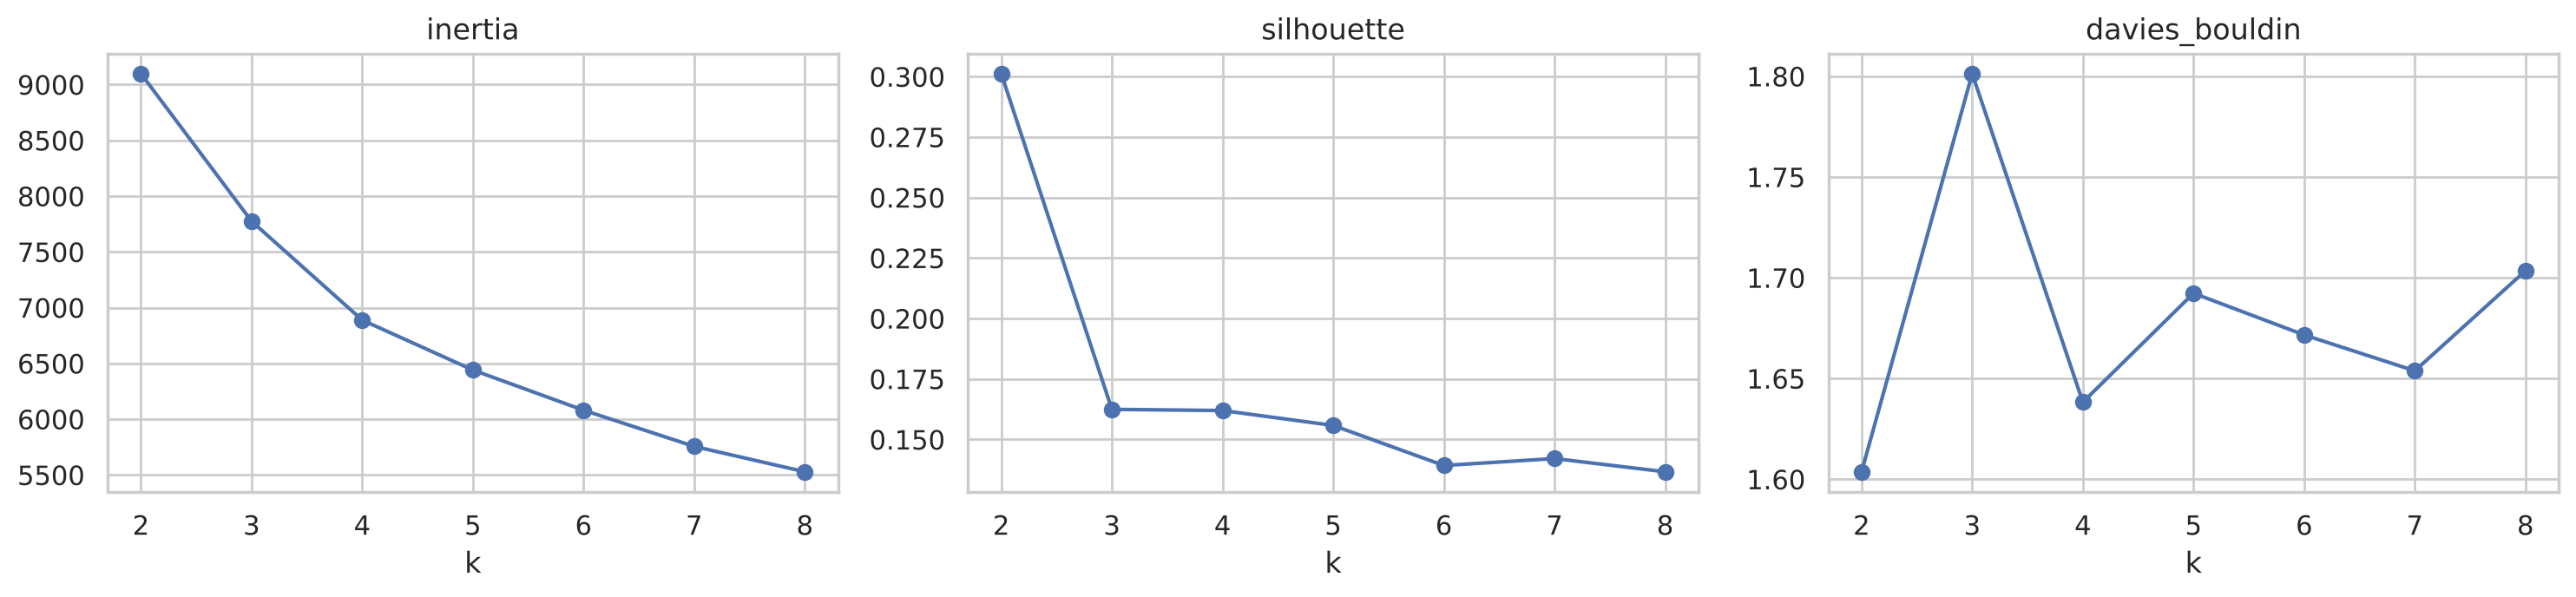

,k,inertia,silhouette,davies_bouldin
0,2,9097.326,0.301,1.604
1,3,7774.647,0.162,1.801
2,4,6888.054,0.162,1.638
3,5,6440.624,0.156,1.692
4,6,6080.143,0.139,1.672
5,7,5755.693,0.142,1.654
6,8,5528.236,0.137,1.703


In [12]:
krange = range(2, 9)
km_scores = []
for k in krange:
    km = KMeans(n_clusters=k, n_init=20, random_state=SEED).fit(Xs)
    km_scores.append({"k": k, "inertia": km.inertia_, "silhouette": silhouette_score(Xs, km.labels_),
                      "davies_bouldin": davies_bouldin_score(Xs, km.labels_)})
km_scores = pd.DataFrame(km_scores)
fig, ax = plt.subplots(1, 3, figsize=(15, 3.6))
for a, col in zip(ax, ["inertia", "silhouette", "davies_bouldin"]):
    a.plot(km_scores.k, km_scores[col], marker="o"); a.set_title(col); a.set_xlabel("k")
savefig("fig4_k_selection")
km_scores.round(3)

In [13]:
def bootstrap_stability(k, B=30):
    base = KMeans(n_clusters=k, n_init=10, random_state=SEED).fit(Xs)
    aris = []
    rng = np.random.default_rng(SEED)
    for b in range(B):
        idx = rng.choice(len(Xs), len(Xs), replace=True)
        kb = KMeans(n_clusters=k, n_init=10, random_state=b).fit(Xs[idx])
        aris.append(adjusted_rand_score(base.labels_, kb.predict(Xs)))
    return np.mean(aris), np.std(aris)

stab = pd.DataFrame([{"k": k, "ARI_mean": m, "ARI_sd": s} for k in range(2, 8) for m, s in [bootstrap_stability(k)]])
km_scores = km_scores.merge(stab, on="k", how="left")
km_scores.to_csv(OUT / "seller_k_selection.csv", index=False)
RESULTS["seller_k_selection"] = km_scores.round(3).to_dict("records")
km_scores.round(3)

,k,inertia,silhouette,davies_bouldin,ARI_mean,ARI_sd
0,2,9097.326,0.301,1.604,0.947,0.047
1,3,7774.647,0.162,1.801,0.808,0.109
2,4,6888.054,0.162,1.638,0.910,0.024
3,5,6440.624,0.156,1.692,0.700,0.182
4,6,6080.143,0.139,1.672,0.701,0.135
5,7,5755.693,0.142,1.654,0.722,0.087
6,8,5528.236,0.137,1.703,NaN,NaN


**Choice of k.** Silhouette values on real, continuous seller data are modest for every k (no strongly separated
groups), so k is chosen by combining (i) a silhouette/Davies–Bouldin that is not materially worse than k=2,
(ii) bootstrap stability (ARI) and (iii) business interpretability — k=2 merely splits large vs small sellers.
k = 2 has the best silhouette but only separates large from small sellers. Among k ≥ 3, **k = 4** ties for the best
silhouette (0.16), has the second-best Davies–Bouldin index and is by far the most stable under bootstrap resampling
(mean ARI ≈ 0.91 vs 0.70–0.81 for k = 3, 5, 6). We therefore use **k = 4**; the low absolute silhouette is stated as a
limitation: segments are useful partitions of a continuum rather than naturally separated groups.

In [14]:
K = 4
km = KMeans(n_clusters=K, n_init=50, random_state=SEED).fit(Xs)
S["segment"] = km.labels_
gmm = GaussianMixture(n_components=K, covariance_type="full", random_state=SEED, n_init=5).fit(Xs)
ward = AgglomerativeClustering(n_clusters=K, linkage="ward").fit(Xs)
agree = {"ARI_kmeans_vs_gmm": adjusted_rand_score(km.labels_, gmm.predict(Xs)),
         "ARI_kmeans_vs_ward": adjusted_rand_score(km.labels_, ward.labels_),
         "silhouette_k4": silhouette_score(Xs, km.labels_)}
RESULTS["seller_cluster_agreement"] = {k: round(v, 3) for k, v in agree.items()}
print(agree)

profile = S.groupby("segment").agg(
    sellers=("revenue", "size"), revenue_share=("revenue", lambda s: s.sum() / S.revenue.sum()),
    median_revenue=("revenue", "median"), median_orders_per_month=("orders_per_month", "median"),
    median_item_price=("avg_item_price", "median"), median_active_months=("active_months", "median"),
    median_categories=("category_breadth", "median"), avg_review=("avg_review", "mean"),
    late_rate=("late_rate", "mean"), median_handling_days=("median_handling_days", "median"),
    after_limit_rate=("after_limit_rate", "mean"), freight_ratio=("freight_ratio", "mean"),
    cancel_rate=("cancel_rate", "mean"), repeat_share=("repeat_customer_share", "mean"))
profile

{'ARI_kmeans_vs_gmm': 0.09088291130768116, 'ARI_kmeans_vs_ward': 0.4260870527472737, 'silhouette_k4': 0.16213554835000005}


,sellers,revenue_share,median_revenue,median_orders_per_month,median_item_price,median_active_months,median_categories,avg_review,late_rate,median_handling_days,after_limit_rate,freight_ratio,cancel_rate,repeat_share
segment,,,,,,,,,,,,,,
0,232,0.078916,2147.695,1.999525,104.221054,9.442838,2.0,3.588862,0.137151,5.042196,0.401557,0.180910,0.017872,0.011280
1,556,0.041294,723.100,2.069206,53.778519,5.845598,2.0,4.256255,0.042351,1.285839,0.047201,0.257121,0.004472,0.006400
2,620,0.269951,3455.900,1.866991,171.632083,9.311432,2.0,4.214912,0.060165,1.402593,0.048197,0.114939,0.005336,0.006729
3,358,0.609840,10404.980,8.295783,91.163030,14.485545,5.0,4.133916,0.060393,1.559988,0.071753,0.184322,0.003575,0.007611


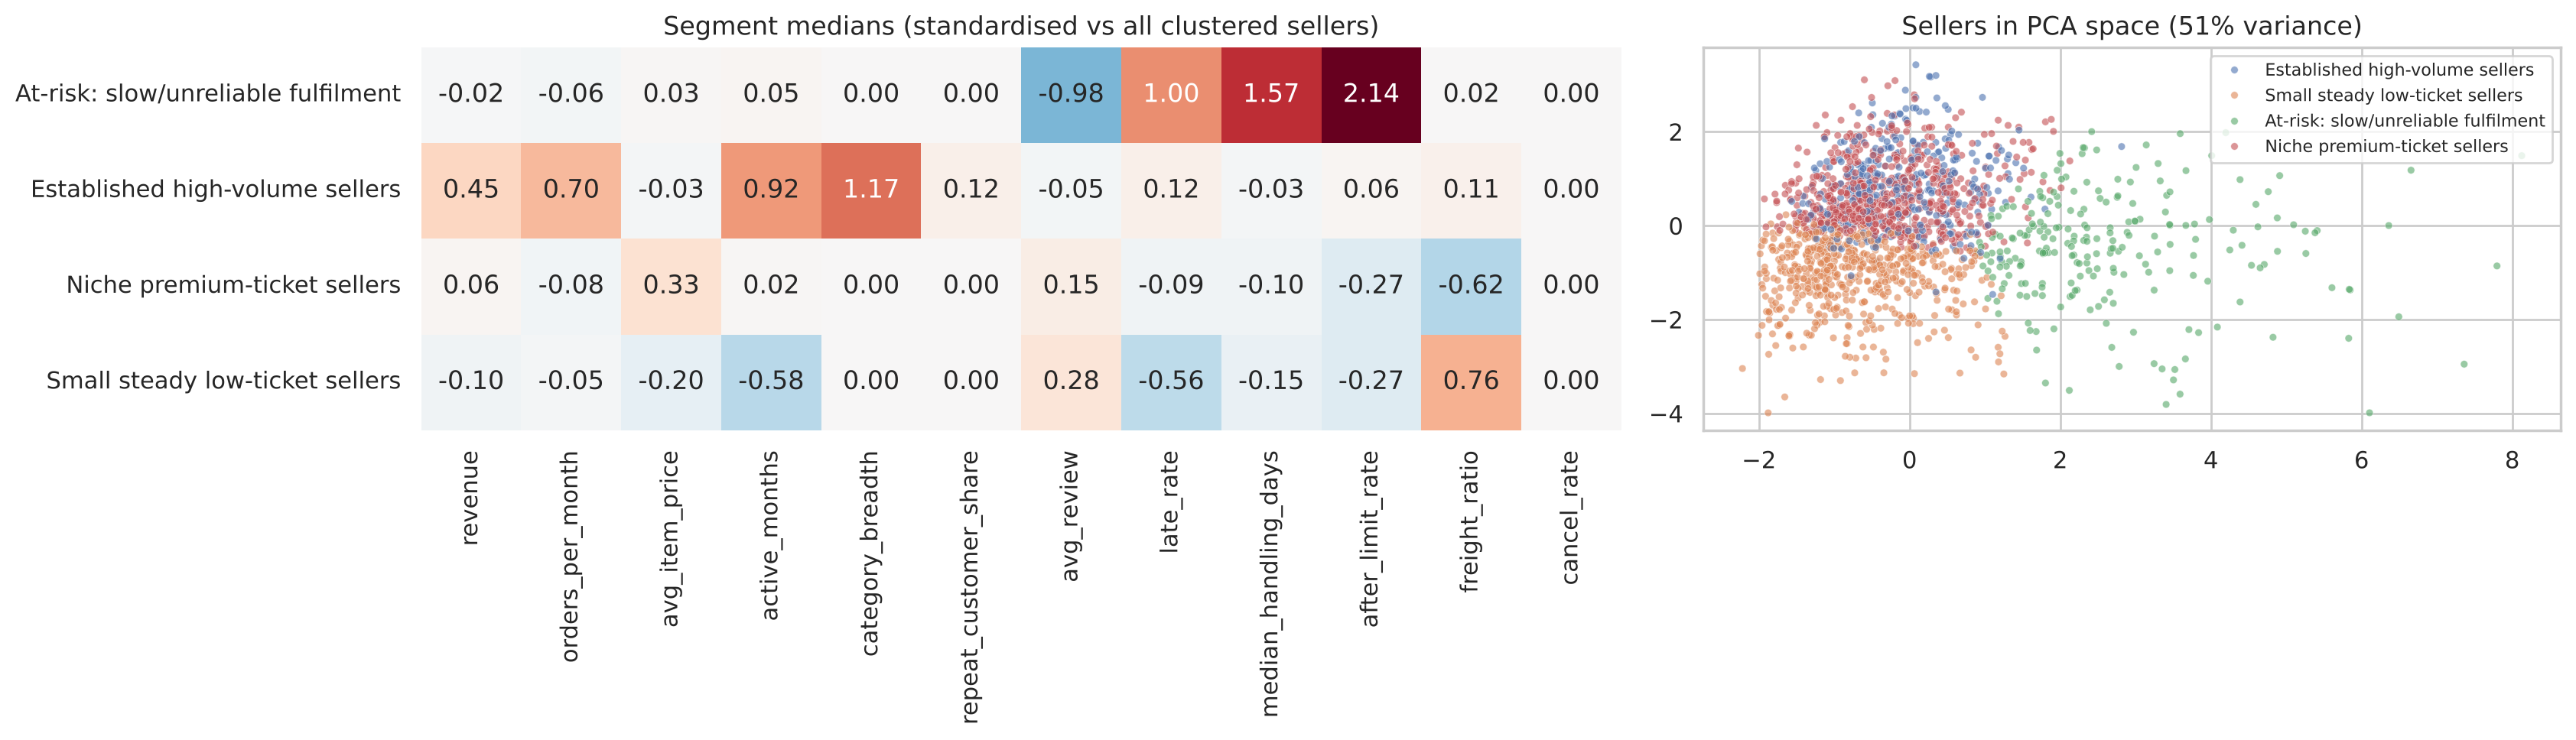

,segment_name,sellers,revenue_share,median_revenue,median_orders_per_month,median_item_price,median_active_months,median_categories,avg_review,late_rate,median_handling_days,after_limit_rate,freight_ratio,cancel_rate,repeat_share
segment,,,,,,,,,,,,,,,
0,At-risk: slow/unreliable fulfilment,232,0.079,2147.695,2.000,104.221,9.443,2.0,3.589,0.137,5.042,0.402,0.181,0.018,0.011
1,Small steady low-ticket sellers,556,0.041,723.100,2.069,53.779,5.846,2.0,4.256,0.042,1.286,0.047,0.257,0.004,0.006
2,Niche premium-ticket sellers,620,0.270,3455.900,1.867,171.632,9.311,2.0,4.215,0.060,1.403,0.048,0.115,0.005,0.007
3,Established high-volume sellers,358,0.610,10404.980,8.296,91.163,14.486,5.0,4.134,0.060,1.560,0.072,0.184,0.004,0.008


In [15]:
# Name segments from their profile (rule-based so names follow the data if the run changes)
p = profile.copy()
names = {}
big = p.median_revenue.idxmax()
names[big] = "Established high-volume sellers"
rest = p.drop(index=big)
worst = rest[["late_rate", "after_limit_rate", "median_handling_days"]].rank().sum(axis=1).idxmax()
names[worst] = "At-risk: slow/unreliable fulfilment"
rest = rest.drop(index=worst)
prem = rest.median_item_price.idxmax()
names[prem] = "Niche premium-ticket sellers"
for s_ in rest.drop(index=prem).index:
    names[s_] = "Small steady low-ticket sellers"
S["segment_name"] = S.segment.map(names)
profile.insert(0, "segment_name", profile.index.map(names))
profile.round(3).to_csv(OUT / "seller_segment_profiles.csv")
RESULTS["seller_profiles"] = profile.round(3).reset_index().to_dict("records")

# z-score heatmap of profiles
heat = S.groupby("segment_name")[feat_cols].median()
heat = (heat - S[feat_cols].median()) / S[feat_cols].std()
fig, ax = plt.subplots(1, 2, figsize=(17, 5), gridspec_kw={"width_ratios": [1.4, 1]})
sns.heatmap(heat, annot=True, fmt=".2f", cmap="RdBu_r", center=0, ax=ax[0], cbar=False)
ax[0].set_title("Segment medians (standardised vs all clustered sellers)"); ax[0].set_ylabel("")
pcs = PCA(2, random_state=SEED).fit(Xs)
Z = pcs.transform(Xs)
sns.scatterplot(x=Z[:, 0], y=Z[:, 1], hue=S.segment_name.values, s=12, alpha=.6, ax=ax[1])
ax[1].set_title(f"Sellers in PCA space ({100*pcs.explained_variance_ratio_.sum():.0f}% variance)")
ax[1].legend(fontsize=8)
savefig("fig5_seller_segments")
profile.round(3)

### 3.1 Sensitivity check
We re-cluster with (a) a minimum of 10 delivered orders instead of 5 and (b) k = 3 and k = 5, and report how the
k=4 assignments map onto these alternatives.

In [16]:
sens3 = {}
mask10 = (S.n_delivered >= 10).values
km10 = KMeans(n_clusters=K, n_init=20, random_state=SEED).fit(Xs[mask10])
sens3["ARI_min10_vs_base"] = adjusted_rand_score(km.labels_[mask10], km10.labels_)
for k in [3, 5]:
    kk = KMeans(n_clusters=k, n_init=20, random_state=SEED).fit(Xs)
    sens3[f"ARI_k{k}_vs_k4"] = adjusted_rand_score(km.labels_, kk.labels_)
    print(f"\nCross-tab k=4 (rows) vs k={k} (cols)")
    print(pd.crosstab(S.segment_name, kk.labels_))
RESULTS["seller_sensitivity"] = {k: round(v, 3) for k, v in sens3.items()}
sens3


Cross-tab k=4 (rows) vs k=3 (cols)
col_0                                  0    1    2
segment_name                                      
At-risk: slow/unreliable fulfilment    3  229    0
Established high-volume sellers      325    4   29
Niche premium-ticket sellers         399   10  211
Small steady low-ticket sellers        1   11  544

Cross-tab k=4 (rows) vs k=5 (cols)
col_0                                  0    1    2    3    4
segment_name                                                
At-risk: slow/unreliable fulfilment   32    4  191    5    0
Established high-volume sellers        7    5    0  345    1
Niche premium-ticket sellers         105  491    0    7   17
Small steady low-ticket sellers      128    0    1    5  422


{'ARI_min10_vs_base': 0.7222047913450296,
 'ARI_k3_vs_k4': 0.4537549615576387,
 'ARI_k5_vs_k4': 0.6986369078828033}

## Task 4 — Unusual orders meriting operational review

Operational review is expensive, so the goal is a **short, explained, ranked list**. We combine two complementary views:

1. **Rule-based integrity flags** — deterministic, auditable conditions that are wrong by definition
   (impossible timestamp order, payment not reconciling with items + freight, delivered without delivery date,
   order approved but never handed to a carrier for >30 days, extreme lateness).
2. **Unsupervised multivariate anomaly scores** — Isolation Forest [7] and Local Outlier Factor [8] on
   log/robust-scaled order features (value, freight ratio, items, sellers, weight, distance, approval delay, handling,
   transit, delivery vs promise, instalments). Consensus between the two detectors reduces false positives.

Validation: since there are no labels for "should have been reviewed", we check that flagged orders are associated
with external signals not used in scoring (low review scores, cancellations).

In [17]:
A = df[(df.order_purchase_timestamp >= "2017-01-01") & (df.order_purchase_timestamp < "2018-09-01") & df.n_items.notna()].copy()
A["delivery_minus_promise"] = A.delivery_days - A.promised_days
rules_flags = pd.DataFrame(index=A.index)
rules_flags["carrier_before_approval"] = A.order_delivered_carrier_date < A.order_approved_at - pd.Timedelta(hours=1)
rules_flags["delivered_before_carrier"] = A.order_delivered_customer_date < A.order_delivered_carrier_date
rules_flags["payment_mismatch"] = A.pay_gap.abs() > np.maximum(1, 0.05 * A.order_value)
rules_flags["delivered_status_no_date"] = (A.order_status == "delivered") & A.order_delivered_customer_date.isna()
rules_flags["stuck_not_shipped_30d"] = A.order_approved_at.notna() & A.order_delivered_carrier_date.isna() & \
    ~A.order_status.isin(["canceled", "unavailable"]) & ((pd.Timestamp("2018-10-17") - A.order_approved_at).dt.days > 30)
rules_flags["extreme_late_30d"] = A.days_late > 30
rules_flags["approval_over_7d"] = A.approval_hours > 24 * 7
A["n_rule_flags"] = rules_flags.sum(axis=1)
A["rule_reasons"] = rules_flags.apply(lambda r: ", ".join(r.index[r.values]), axis=1)
rule_counts = rules_flags.sum().sort_values(ascending=False)
RESULTS["anomaly_rule_counts"] = rule_counts.to_dict()
RESULTS["anomaly_rule_any"] = int((A.n_rule_flags > 0).sum())
rule_counts

carrier_before_approval     1117
stuck_not_shipped_30d        599
extreme_late_30d             344
payment_mismatch             210
approval_over_7d              72
delivered_before_carrier      19
delivered_status_no_date       8
dtype: int64

In [18]:
an_cols = ["order_value", "freight_ratio", "n_items", "n_sellers", "max_price", "weight_g", "distance_km",
           "approval_hours", "handling_days", "transit_days", "delivery_minus_promise", "installments", "n_payment_rows"]
D = A[A.order_status == "delivered"].dropna(subset=["delivery_days"]).copy()
Xa = D[an_cols].copy()
for c in ["order_value", "max_price", "weight_g", "distance_km", "approval_hours"]:
    Xa[c] = np.log1p(Xa[c].clip(lower=0))
for c in ["handling_days", "transit_days"]:
    Xa[c] = np.sign(Xa[c]) * np.log1p(Xa[c].abs())
Xa = Xa.fillna(Xa.median())
Xa_s = RobustScaler().fit_transform(Xa)
CONT = 0.01
iso = IsolationForest(n_estimators=300, contamination=CONT, random_state=SEED, n_jobs=-1).fit(Xa_s)
D["iso_score"] = -iso.score_samples(Xa_s)
lof = LocalOutlierFactor(n_neighbors=35, contamination=CONT, n_jobs=-1).fit(Xa_s)
D["lof_score"] = -lof.negative_outlier_factor_
D["iso_flag"] = D.iso_score >= D.iso_score.quantile(1 - CONT)
D["lof_flag"] = D.lof_score >= D.lof_score.quantile(1 - CONT)
D["consensus_rank"] = (D.iso_score.rank(pct=True) + D.lof_score.rank(pct=True)) / 2
D["consensus_flag"] = D.consensus_rank >= D.consensus_rank.quantile(1 - CONT)
both = (D.iso_flag & D.lof_flag).sum()
jacc = both / (D.iso_flag | D.lof_flag).sum()
sp = stats.spearmanr(D.iso_score, D.lof_score).correlation
RESULTS["anomaly_detectors"] = {"n_scored": len(D), "iso_flagged": int(D.iso_flag.sum()), "lof_flagged": int(D.lof_flag.sum()),
                                "both": int(both), "jaccard": round(jacc, 3), "spearman_scores": round(sp, 3)}
RESULTS["anomaly_detectors"]

{'n_scored': 96203,
 'iso_flagged': 963,
 'lof_flagged': 963,
 'both': 169,
 'jaccard': np.float64(0.096),
 'spearman_scores': np.float64(0.511)}

In [19]:
# Explain each flagged order: which features deviate most (robust z-score)
med = Xa.median(); iqr = (Xa.quantile(.75) - Xa.quantile(.25)).replace(0, 1)
Zr = (Xa - med) / iqr
def reasons(idx, k=3):
    z = Zr.loc[idx].abs().sort_values(ascending=False).head(k)
    return "; ".join(f"{c} ({D.loc[idx, c]:.1f})" for c in z.index)
flag = D[D.consensus_flag].copy()
flag["top_drivers"] = [reasons(i) for i in flag.index]
driver_freq = pd.Series([r.split(" (")[0] for s in flag.top_drivers for r in s.split("; ")]).value_counts()
RESULTS["anomaly_driver_freq"] = driver_freq.head(8).to_dict()
print("Most frequent drivers among consensus-flagged orders:\n", driver_freq.head(10))

# External validation: are flagged orders worse on signals NOT used in scoring?
val = D.groupby("consensus_flag").agg(n=("order_id", "size"), mean_review=("review_score", "mean"),
                                      low_review_rate=("review_score", lambda s: (s <= 2).mean()))
mw = stats.mannwhitneyu(D.loc[D.consensus_flag, "review_score"].dropna(), D.loc[~D.consensus_flag, "review_score"].dropna(), alternative="less")
RESULTS["anomaly_validation"] = {"table": val.round(3).reset_index().to_dict("records"), "mannwhitney_p": float(f"{mw.pvalue:.3g}")}
print(val.round(3)); print("Mann-Whitney (flagged reviews lower) p =", mw.pvalue)

Most frequent drivers among consensus-flagged orders:
 delivery_minus_promise    344
order_value               313
installments              286
max_price                 268
freight_ratio             248
n_items                   247
distance_km               244
handling_days             242
transit_days              198
weight_g                  180
Name: count, dtype: int64
                    n  mean_review  low_review_rate
consensus_flag                                     
False           95240        4.165            0.125
True              963        3.273            0.355
Mann-Whitney (flagged reviews lower) p = 6.739576889682453e-65


priority
P1: rule + statistical     144
P2: multiple rules          21
P3: single rule           2173
P4: statistical only       819
Name: count, dtype: int64


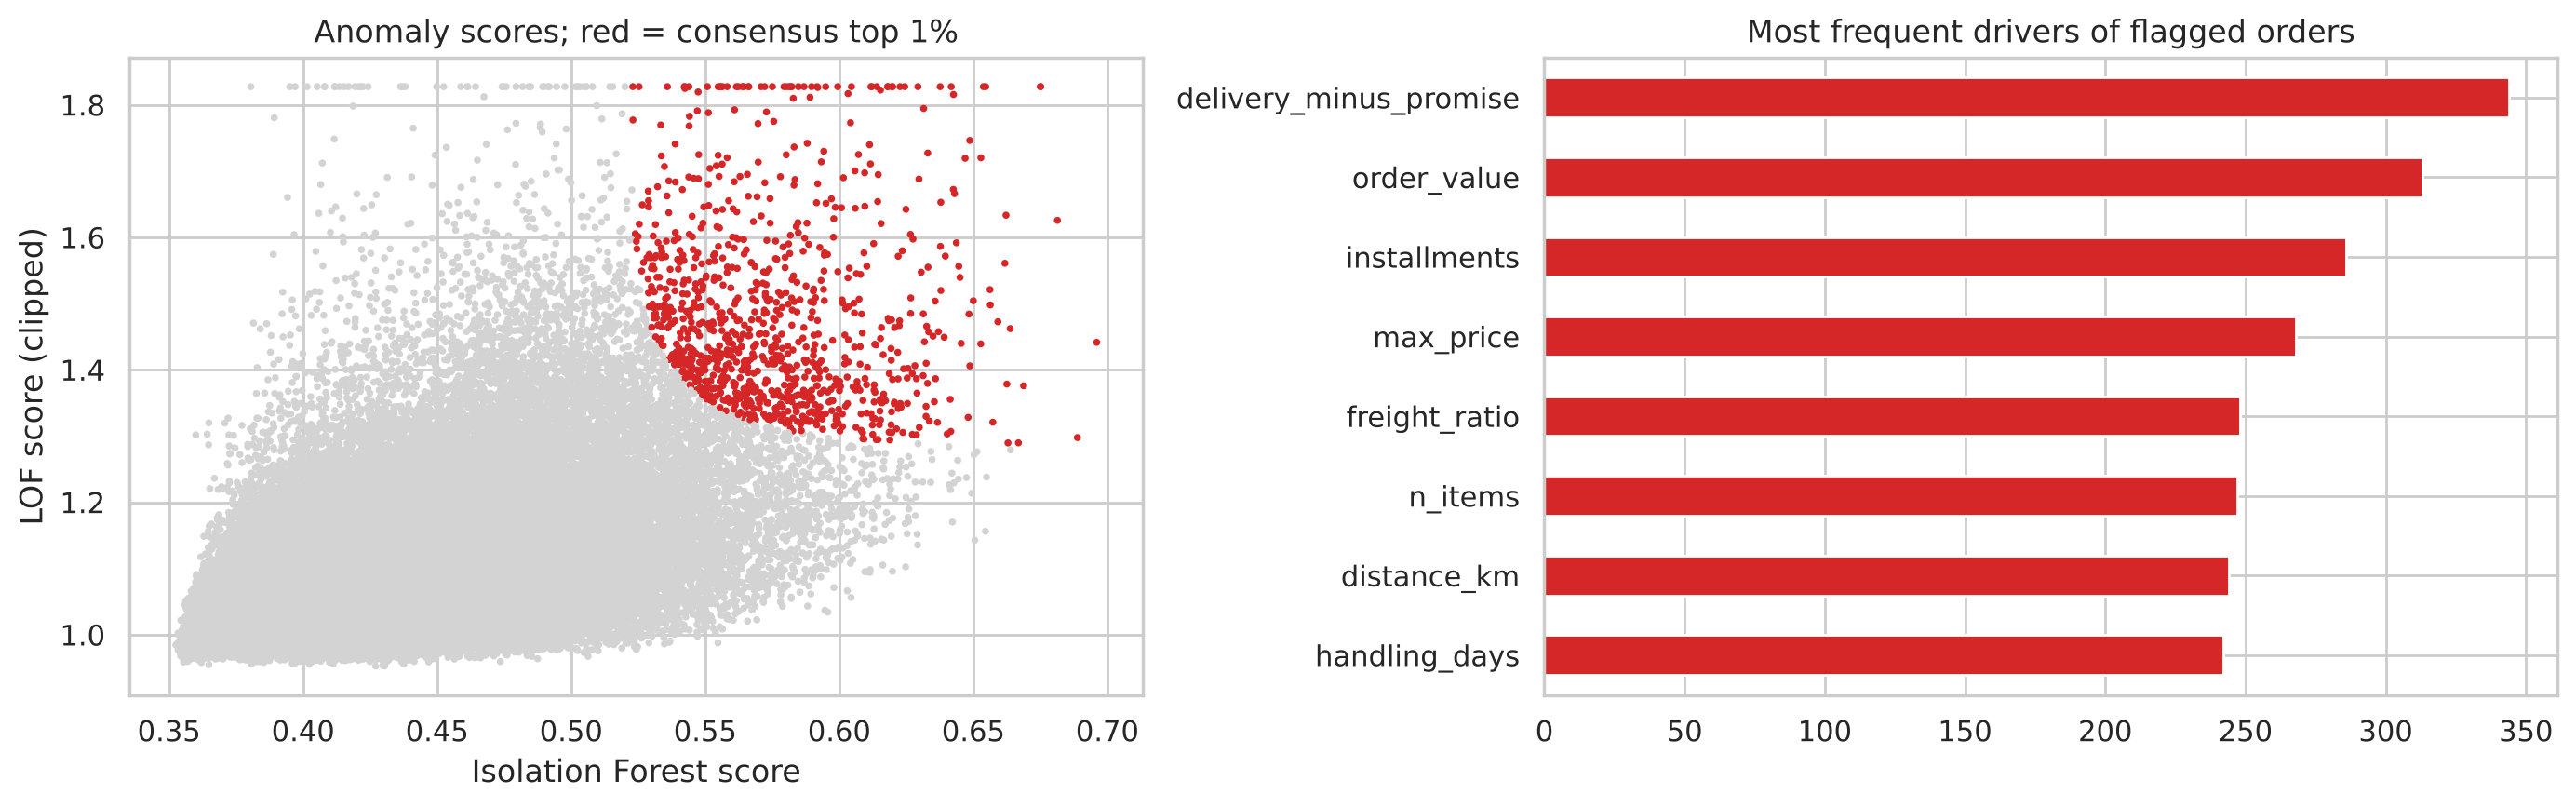

,order_id,priority,order_status,order_value,freight_ratio,n_items,delivery_days,promised_days,days_late,review_score,rule_reasons,top_drivers
41181,b866af202be0692766081310cd4085e1,P1: rule + statistical,delivered,206.65,0.087104,2.0,18.537836,79.375498,-61.0,4.0,delivered_before_carrier,delivery_minus_promise (-60.8); transit_days (...
14314,dceb62e8fa94b46006c9554fed743df0,P1: rule + statistical,delivered,330.07,0.155361,3.0,5.882697,21.126331,-16.0,2.0,delivered_before_carrier,transit_days (-6.0); n_payment_rows (4.0); n_i...
41138,8554cb37f7158cb0b082a841d24a4589,P1: rule + statistical,delivered,1299.28,0.038321,2.0,7.060428,30.221713,-24.0,1.0,"carrier_before_approval, approval_over_7d",handling_days (-9.1); installments (10.0); ord...
25364,e37f11cae9985ca58f0b56f268720537,P1: rule + statistical,delivered,220.85,0.517319,7.0,5.252338,28.509329,-24.0,5.0,delivered_before_carrier,n_items (7.0); transit_days (-1.0); freight_ra...
80536,d731191f76c39fe5c7d22edddb6836ba,P1: rule + statistical,delivered,164.40,0.367397,4.0,58.911181,23.240370,35.0,NaN,extreme_late_30d,delivery_minus_promise (35.7); n_items (4.0); ...
34828,97f48024fcc76f1898e397ad6966e3a0,P1: rule + statistical,delivered,1354.09,0.070224,1.0,107.064699,26.482639,80.0,4.0,extreme_late_30d,delivery_minus_promise (80.6); handling_days (...
23913,df720130627bfe896e4eaafe2df5b721,P1: rule + statistical,delivered,371.42,0.122287,1.0,4.195336,36.381007,-33.0,5.0,carrier_before_approval,distance_km (8.5); delivery_minus_promise (-32...
47092,cf5c8d9f52807cb2d2f0a0ff54c478da,P1: rule + statistical,delivered,217.18,0.248596,6.0,6.255382,41.455498,-36.0,1.0,carrier_before_approval,n_items (6.0); n_sellers (5.0); delivery_minus...
35912,da81fbc27b55e0f3d2813cf2078dc780,P1: rule + statistical,delivered,1755.35,0.032102,1.0,126.132627,26.119502,100.0,4.0,extreme_late_30d,delivery_minus_promise (100.0); handling_days ...
34555,c1e2bf2b7dd3309f2f5356c6b63968fa,P1: rule + statistical,delivered,326.78,0.137065,2.0,4.206100,32.570023,-29.0,4.0,delivered_before_carrier,transit_days (-16.1); handling_days (20.3); de...


In [20]:
# Final review queue: rule flags (all statuses) + consensus statistical flags, prioritised
A = A.merge(D[["order_id", "iso_score", "lof_score", "consensus_rank", "consensus_flag"]], on="order_id", how="left")
A["consensus_flag"] = A.consensus_flag.fillna(False).astype(bool)
A = A.merge(flag[["order_id", "top_drivers"]], on="order_id", how="left")
A["priority"] = np.select([(A.n_rule_flags > 0) & A.consensus_flag, A.n_rule_flags >= 2, A.n_rule_flags == 1, A.consensus_flag],
                          ["P1: rule + statistical", "P2: multiple rules", "P3: single rule", "P4: statistical only"], "none")
queue = A[A.priority != "none"].sort_values(["priority", "consensus_rank"], ascending=[True, False])
qcols = ["order_id", "priority", "order_status", "order_value", "freight_ratio", "n_items", "delivery_days", "promised_days",
         "days_late", "review_score", "rule_reasons", "top_drivers"]
queue[qcols].to_csv(OUT / "unusual_orders_review_queue.csv", index=False)
RESULTS["anomaly_queue_counts"] = queue.priority.value_counts().sort_index().to_dict()
RESULTS["anomaly_queue_examples"] = queue[qcols].head(6).round(2).astype(str).to_dict("records")
print(queue.priority.value_counts().sort_index())

fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
ax[0].scatter(D.iso_score, D.lof_score.clip(upper=D.lof_score.quantile(.999)), s=3, c=D.consensus_flag.map({True: "tab:red", False: "lightgrey"}))
ax[0].set_xlabel("Isolation Forest score"); ax[0].set_ylabel("LOF score (clipped)"); ax[0].set_title("Anomaly scores; red = consensus top 1%")
driver_freq.head(8)[::-1].plot.barh(ax=ax[1], color="tab:red"); ax[1].set_title("Most frequent drivers of flagged orders")
savefig("fig6_anomalies")
queue[qcols].head(10)

### 4.1 Sensitivity: contamination level
The 1% cut-off is a capacity assumption (≈ 50 orders per month at observed volume). We check how much the flagged set
changes at 0.5% and 2%.

In [21]:
sens4 = []
for c in [0.005, 0.01, 0.02]:
    f_ = D.consensus_rank >= D.consensus_rank.quantile(1 - c)
    sens4.append({"contamination": c, "n_flagged": int(f_.sum()), "mean_review_flagged": round(D.loc[f_, "review_score"].mean(), 3),
                  "share_of_1pct_set_retained": round((f_ & D.consensus_flag).sum() / D.consensus_flag.sum(), 3)})
RESULTS["anomaly_sensitivity"] = sens4
pd.DataFrame(sens4)

,contamination,n_flagged,mean_review_flagged,share_of_1pct_set_retained
0,0.005,482,3.068,0.501
1,0.010,963,3.273,1.000
2,0.020,1925,3.384,1.000


## Task 5 — Predicting late delivery and delivery time

### 5.1 Design
* **Unit:** delivered orders purchased Jan 2017 – Aug 2018 (edge months excluded, see 1.4).
* **Targets:** `late` (binary) and `delivery_days` (continuous, purchase → delivery).
* **No leakage:** only information available at the moment of purchase is used. Carrier/delivery timestamps,
  reviews and approval timing are excluded. Seller, route and network history features are computed **only from orders
  already delivered before the current purchase timestamp** (time-aware, via `merge_asof`), so they mimic what Olist
  would actually know when the customer clicks "buy".
* **Validation:** an out-of-time split — train: Jan 2017–Mar 2018, validation: Apr–May 2018 (threshold/early-stopping),
  test: Jun–Aug 2018. Final models are refit on train+valid with the early-stopped number of trees. Because a single
  3-month window can be unrepresentative, a **rolling-origin** evaluation (retrain monthly, predict next month,
  Oct 2017–Aug 2018) is reported as the primary robustness check. A random 5-fold CV is reported as a sensitivity comparison to show how much
  random splitting would overstate performance.
* **Baselines:** constant prevalence and a no-fit domain heuristic — the route's historical mean delivery time divided
  by the promised days (classification); training median, Olist's promised days and the route's historical mean
  (regression). **Models:** regularised logistic / ridge regression and gradient-boosted trees (LightGBM [9]).
* **Metrics:** PR-AUC (primary for a ~8% positive class [10]), ROC-AUC, Brier score, precision/recall/F1 at a
  validation-chosen threshold; MAE (primary, in days), RMSE, R².

In [22]:
M = dl.copy().sort_values("order_purchase_timestamp").reset_index(drop=True)

# time-aware seller history: events = deliveries of the seller's previous orders
hist = M[["seller_id", "order_delivered_customer_date", "late", "delivery_days", "handling_days"]].dropna(subset=["seller_id"]).sort_values("order_delivered_customer_date")
hist["one"] = 1
g = hist.groupby("seller_id")
hist["cum_n"] = g.one.cumsum(); hist["cum_late"] = g.late.cumsum(); hist["cum_days"] = g.delivery_days.cumsum()
hist["cum_handling"] = g.handling_days.cumsum()
hist = hist.rename(columns={"order_delivered_customer_date": "event_ts"})[["seller_id", "event_ts", "cum_n", "cum_late", "cum_days", "cum_handling"]]
M = pd.merge_asof(M.sort_values("order_purchase_timestamp"), hist.sort_values("event_ts"),
                  left_on="order_purchase_timestamp", right_on="event_ts", by="seller_id", direction="backward", allow_exact_matches=False)
for c in ["cum_n", "cum_late", "cum_days", "cum_handling"]:
    M[c] = M[c].fillna(0)
PRIOR_N = 10
glob_late = M.loc[M.order_purchase_timestamp < "2018-04-01", "late"].mean()
glob_days = M.loc[M.order_purchase_timestamp < "2018-04-01", "delivery_days"].mean()
M["seller_prior_orders"] = M.cum_n
M["seller_prior_late_rate"] = (M.cum_late + PRIOR_N * glob_late) / (M.cum_n + PRIOR_N)  # shrunk (empirical-Bayes style)
M["seller_prior_mean_days"] = (M.cum_days + PRIOR_N * glob_days) / (M.cum_n + PRIOR_N)
M["seller_prior_handling"] = np.where(M.cum_n > 0, M.cum_handling / M.cum_n.replace(0, 1), np.nan)

# time-aware ROUTE history (seller state -> customer state), same construction as seller history
M["route"] = M.seller_state.fillna("NA") + "->" + M.customer_state.fillna("NA")
rh = M[["route", "order_delivered_customer_date", "late", "delivery_days"]].sort_values("order_delivered_customer_date").copy()
rh["one"] = 1; gr = rh.groupby("route")
rh["r_n"] = gr.one.cumsum(); rh["r_late"] = gr.late.cumsum(); rh["r_days"] = gr.delivery_days.cumsum()
rh = rh.rename(columns={"order_delivered_customer_date": "r_ts"})[["route", "r_ts", "r_n", "r_late", "r_days"]]
M = pd.merge_asof(M.sort_values("order_purchase_timestamp"), rh, left_on="order_purchase_timestamp", right_on="r_ts",
                  by="route", direction="backward", allow_exact_matches=False)
for c in ["r_n", "r_late", "r_days"]:
    M[c] = M[c].fillna(0)
M["route_prior_orders"] = M.r_n
M["route_prior_late_rate"] = (M.r_late + PRIOR_N * glob_late) / (M.r_n + PRIOR_N)
M["route_prior_mean_days"] = (M.r_days + PRIOR_N * glob_days) / (M.r_n + PRIOR_N)

# NETWORK conditions: orders delivered in the 14 days before purchase (known at purchase time)
ev = M[["order_delivered_customer_date", "late", "delivery_days"]].sort_values("order_delivered_customer_date").copy()
ev["g_n"] = np.arange(1, len(ev) + 1); ev["g_late"] = ev.late.cumsum(); ev["g_days"] = ev.delivery_days.cumsum()
ev = ev.rename(columns={"order_delivered_customer_date": "g_ts"})[["g_ts", "g_n", "g_late", "g_days"]]
now = pd.merge_asof(M[["order_purchase_timestamp"]].reset_index(), ev, left_on="order_purchase_timestamp", right_on="g_ts", direction="backward").set_index("index")
past = M[["order_purchase_timestamp"]].copy(); past["t14"] = past.order_purchase_timestamp - pd.Timedelta(days=14)
past = pd.merge_asof(past.reset_index().sort_values("t14"), ev, left_on="t14", right_on="g_ts", direction="backward").set_index("index")
wn = (now.g_n - past.g_n.fillna(0)).reindex(M.index)
M["net_recent_n"] = wn
M["net_recent_late_rate"] = ((now.g_late - past.g_late.fillna(0)).reindex(M.index) / wn.replace(0, np.nan))
M["net_recent_mean_days"] = ((now.g_days - past.g_days.fillna(0)).reindex(M.index) / wn.replace(0, np.nan))

# calendar features known at purchase
M["p_month"] = M.order_purchase_timestamp.dt.month
M["p_dow"] = M.order_purchase_timestamp.dt.dayofweek
M["p_hour"] = M.order_purchase_timestamp.dt.hour
daily = M.set_index("order_purchase_timestamp").resample("D").size()
roll7 = daily.rolling(7, min_periods=1).mean().shift(1)  # orders/day over previous 7 days
M["demand_prev7d"] = M.order_purchase_timestamp.dt.floor("D").map(roll7)
M["promised_days_int"] = M.promised_days
M["days_to_shipping_limit"] = (M.shipping_limit - M.order_purchase_timestamp).dt.total_seconds() / 86400

# SLACK: how generous is the promise relative to what the route / seller / network currently deliver?
M["slack_vs_route"] = M.promised_days - M.route_prior_mean_days
M["slack_vs_seller"] = M.promised_days - M.seller_prior_mean_days
M["slack_vs_network"] = M.promised_days - M.net_recent_mean_days
M["promise_ratio_route"] = M.route_prior_mean_days / M.promised_days

num_feats = ["promised_days_int", "days_to_shipping_limit", "distance_km", "same_state", "freight", "items_price", "freight_ratio",
             "n_items", "n_sellers", "n_products", "weight_g", "volume_cm3", "installments", "photos", "desc_len",
             "seller_prior_orders", "seller_prior_late_rate", "seller_prior_mean_days", "seller_prior_handling",
             "route_prior_orders", "route_prior_late_rate", "route_prior_mean_days",
             "net_recent_late_rate", "net_recent_mean_days",
             "slack_vs_route", "slack_vs_seller", "slack_vs_network", "promise_ratio_route",
             "p_dow", "p_hour", "c_lat", "c_lng", "s_lat", "s_lng"]
cat_feats = ["customer_state", "seller_state", "main_category", "pay_type"]
# NOTE: month-of-year and recent order volume ("demand_prev7d") were in the first specification but are excluded:
# with <2 years of data, month-of-year cannot generalise, and demand co-moved with the Feb–Mar 2018 lateness spike,
# producing a model that failed out of time (see ablation 5.4).
tr = M.order_purchase_timestamp < "2018-04-01"
va = (M.order_purchase_timestamp >= "2018-04-01") & (M.order_purchase_timestamp < "2018-06-01")
te = (M.order_purchase_timestamp >= "2018-06-01") & (M.order_purchase_timestamp < "2018-09-01")
split_info = pd.DataFrame({"n": [tr.sum(), va.sum(), te.sum()],
                           "late_rate": [M.loc[tr, "late"].mean(), M.loc[va, "late"].mean(), M.loc[te, "late"].mean()],
                           "mean_days": [M.loc[tr, "delivery_days"].mean(), M.loc[va, "delivery_days"].mean(), M.loc[te, "delivery_days"].mean()]},
                          index=["train (Jan17–Mar18)", "valid (Apr–May18)", "test (Jun–Aug18)"])
RESULTS["model_splits"] = split_info.round(4).reset_index().to_dict("records")
split_info.round(4)

,n,late_rate,mean_days
train (Jan17–Mar18),64053,0.0798,13.9012
valid (Apr–May18),13547,0.0553,11.4593
test (Jun–Aug18),18603,0.0361,8.6321


In [23]:
for c in cat_feats:
    M[c] = M[c].fillna("NA").astype("category")
Xall = M[num_feats + cat_feats]
y_late = M.late.astype(int).values
y_days = M.delivery_days.values

def cls_metrics(y, p, thr):
    yhat = (p >= thr).astype(int)
    return {"PR_AUC": average_precision_score(y, p), "ROC_AUC": roc_auc_score(y, p), "Brier": brier_score_loss(y, p) if (p.min() >= 0 and p.max() <= 1) else np.nan,
            "precision": precision_score(y, yhat, zero_division=0), "recall": recall_score(y, yhat), "F1": f1_score(y, yhat)}

def best_thr(y, p):
    pr, rc, th = precision_recall_curve(y, p)
    f1 = 2 * pr * rc / (pr + rc + 1e-12)
    return th[np.nanargmax(f1[:-1])]

pre_lin = ColumnTransformer([
    ("num", make_pipeline(SimpleImputer(strategy="median"), StandardScaler()), num_feats),
    ("cat", OneHotEncoder(handle_unknown="ignore", min_frequency=30), cat_feats)])

res_cls = {}
# Baseline 1: prevalence (constant) – PR-AUC equals prevalence
p_const = np.full(te.sum(), y_late[tr].mean())
res_cls["Baseline: constant prevalence"] = cls_metrics(y_late[te], p_const, 0.5)
# Baseline 2: domain heuristic — risk = route's historical mean delivery days / promised days (time-aware, no fitting)
route_med = M[tr].groupby("route", observed=True).delivery_days.median()
ratio = M.promise_ratio_route
res_cls["Baseline: heuristic (route history ÷ promise)"] = cls_metrics(y_late[te], ratio[te].values, best_thr(y_late[va], ratio[va].values))
# Logistic regression
logit = make_pipeline(pre_lin, LogisticRegression(max_iter=3000, C=0.5))
logit.fit(Xall[tr], y_late[tr])
p_lr_va, p_lr_te = logit.predict_proba(Xall[va])[:, 1], logit.predict_proba(Xall[te])[:, 1]
thr_lr = best_thr(y_late[va], p_lr_va)
res_cls["Logistic regression (train only)"] = cls_metrics(y_late[te], p_lr_te, thr_lr)
trva = (tr | va)
logit_f = make_pipeline(pre_lin, LogisticRegression(max_iter=3000, C=0.5)).fit(Xall[trva], y_late[trva])
p_lr_te = logit_f.predict_proba(Xall[te])[:, 1]
res_cls["Logistic regression (refit train+valid)"] = cls_metrics(y_late[te], p_lr_te, thr_lr)
# LightGBM
lgb_params = dict(n_estimators=2000, learning_rate=0.03, num_leaves=31, min_child_samples=50, subsample=0.8, subsample_freq=1,
                  colsample_bytree=0.8, reg_lambda=1.0, random_state=SEED, verbose=-1)
clf = lgb.LGBMClassifier(**lgb_params)
clf.fit(Xall[tr], y_late[tr], eval_set=[(Xall[va], y_late[va])], eval_metric="average_precision",
        callbacks=[lgb.early_stopping(100, verbose=False)])
p_gb_va, p_gb_te = clf.predict_proba(Xall[va])[:, 1], clf.predict_proba(Xall[te])[:, 1]
thr_gb = best_thr(y_late[va], p_gb_va)
BEST_IT_CLS = int(clf.best_iteration_ or 300)
res_cls["LightGBM (train only)"] = cls_metrics(y_late[te], p_gb_te, thr_gb)
# final model: refit on train+valid with the early-stopped number of trees (standard for time series)
clf = lgb.LGBMClassifier(**{**lgb_params, "n_estimators": BEST_IT_CLS}).fit(Xall[trva], y_late[trva])
p_gb_te = clf.predict_proba(Xall[te])[:, 1]
res_cls["LightGBM (refit train+valid)"] = cls_metrics(y_late[te], p_gb_te, thr_gb)
res_cls = pd.DataFrame(res_cls).T
RESULTS["late_test_metrics"] = res_cls.round(4).reset_index().to_dict("records")
RESULTS["late_test_prevalence"] = round(y_late[te].mean(), 4)
RESULTS["lgb_best_iter_cls"] = BEST_IT_CLS
res_cls.round(4)

,PR_AUC,ROC_AUC,Brier,precision,recall,F1
Baseline: constant prevalence,0.0361,0.5000,0.0367,0.0000,0.0000,0.0000
Baseline: heuristic (route history ÷ promise),0.1338,0.7730,NaN,0.0791,0.7411,0.1429
Logistic regression (train only),0.0940,0.7292,0.0466,0.0796,0.5818,0.1401
Logistic regression (refit train+valid),0.0878,0.7180,0.0371,0.0930,0.2500,0.1356
LightGBM (train only),0.0570,0.6554,0.0422,0.0591,0.1399,0.0831
LightGBM (refit train+valid),0.0572,0.6413,0.0388,0.0751,0.1101,0.0893


In [24]:
res_reg = {}
def reg_metrics(y, p):
    return {"MAE": mean_absolute_error(y, p), "RMSE": mean_squared_error(y, p) ** 0.5, "R2": r2_score(y, p),
            "MedianAE": np.median(np.abs(y - p))}
res_reg["Baseline: training median"] = reg_metrics(y_days[te], np.full(te.sum(), np.median(y_days[tr])))
res_reg["Baseline: Olist promised days"] = reg_metrics(y_days[te], M.promised_days[te].values)
res_reg["Baseline: route historical mean (time-aware)"] = reg_metrics(y_days[te], M.route_prior_mean_days[te].values)
ridge = make_pipeline(pre_lin, Ridge(alpha=10.0))
ridge.fit(Xall[tr], np.log1p(y_days[tr]))
res_reg["Ridge, log target (train only)"] = reg_metrics(y_days[te], np.expm1(ridge.predict(Xall[te])))
ridge.fit(Xall[trva], np.log1p(y_days[trva]))
res_reg["Ridge, log target (refit train+valid)"] = reg_metrics(y_days[te], np.expm1(ridge.predict(Xall[te])))
reg = lgb.LGBMRegressor(objective="l1", **lgb_params)
reg.fit(Xall[tr], y_days[tr], eval_set=[(Xall[va], y_days[va])], eval_metric="l1", callbacks=[lgb.early_stopping(100, verbose=False)])
pd_va, pd_te = reg.predict(Xall[va]), reg.predict(Xall[te])
res_reg["LightGBM L1 (train only)"] = reg_metrics(y_days[te], pd_te)
reg_f = lgb.LGBMRegressor(objective="l1", **{**lgb_params, "n_estimators": reg.best_iteration_ or 300}).fit(Xall[trva], y_days[trva])
pd_te = reg_f.predict(Xall[te])
res_reg["LightGBM L1 (refit train+valid)"] = reg_metrics(y_days[te], pd_te)
res_reg = pd.DataFrame(res_reg).T
RESULTS["days_test_metrics"] = res_reg.round(3).reset_index().to_dict("records")
res_reg.round(3)

,MAE,RMSE,R2,MedianAE
Baseline: training median,5.209,6.545,-0.264,4.754
Baseline: Olist promised days,12.718,15.430,-6.026,11.370
Baseline: route historical mean (time-aware),5.277,6.556,-0.268,4.905
"Ridge, log target (train only)",4.503,6.554,-0.268,3.254
"Ridge, log target (refit train+valid)",3.726,5.547,0.092,2.714
LightGBM L1 (train only),4.843,6.426,-0.219,3.931
LightGBM L1 (refit train+valid),3.841,5.436,0.128,2.997


### 5.2 Diagnostics: calibration, residuals, error by segment, prediction intervals

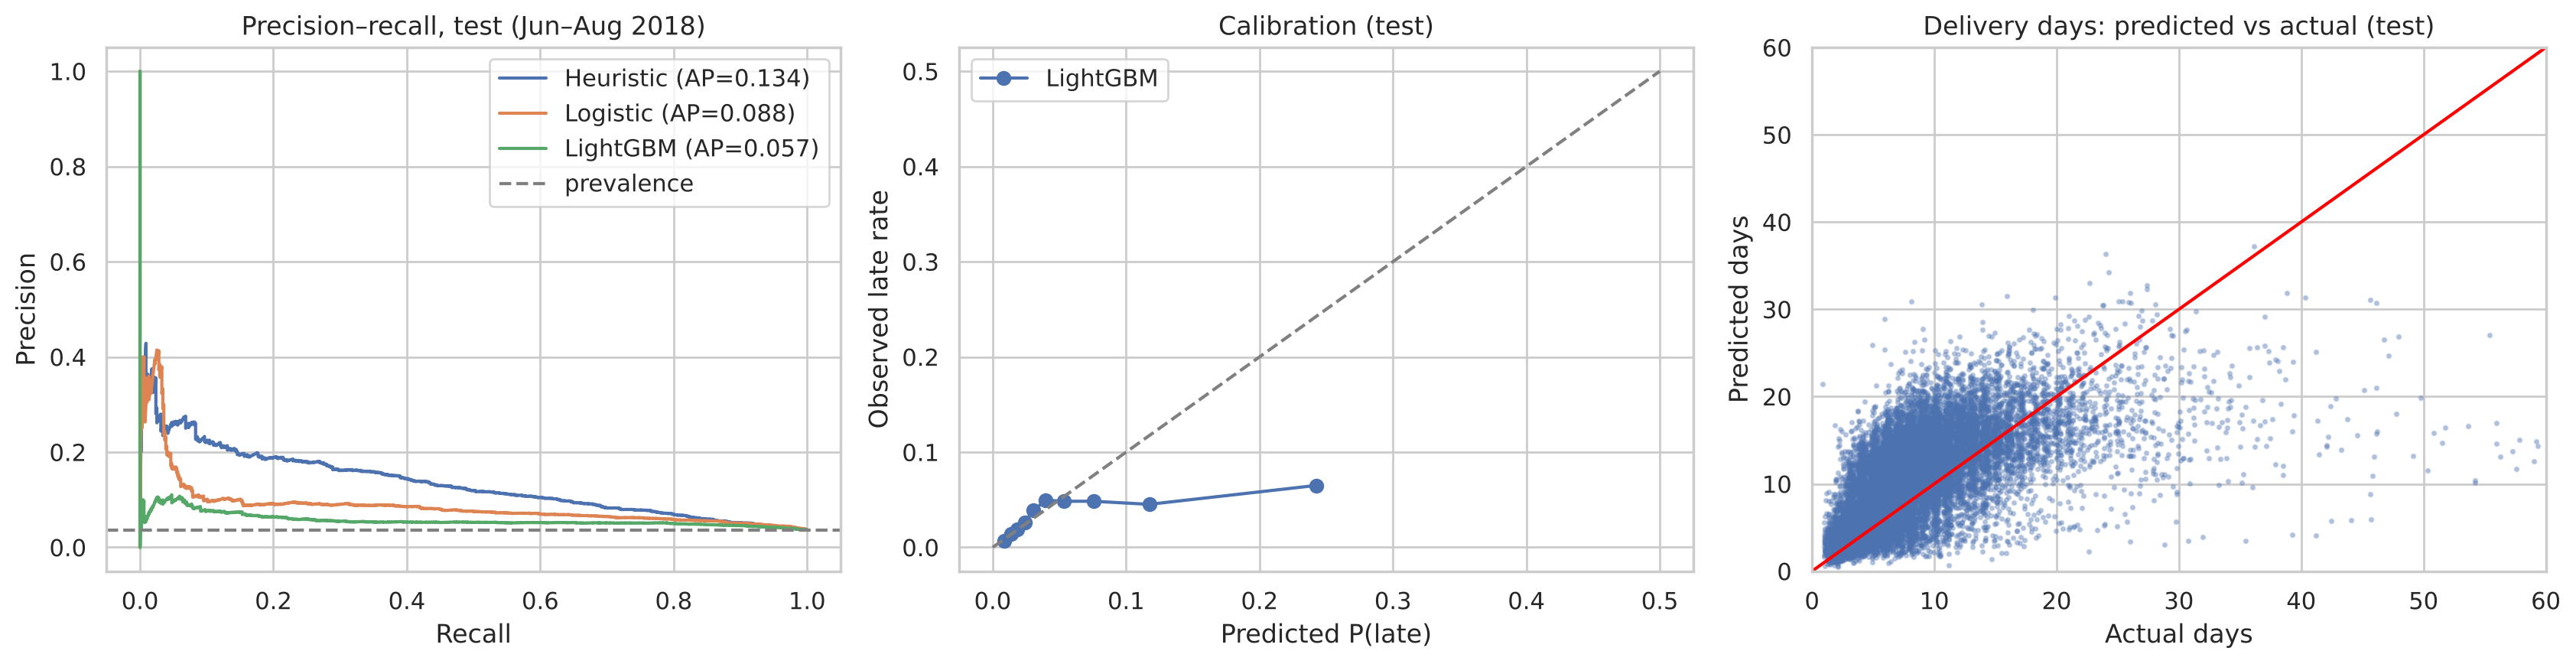

,n,MAE,late_rate
state,,,
SP,8611,2.526,0.047
PR,947,4.113,0.017
GO,334,4.185,0.027
DF,455,4.359,0.029
MG,2058,4.543,0.010
RS,905,4.591,0.020
SC,601,4.826,0.017
ES,348,4.881,0.040
RJ,2126,5.085,0.032


In [25]:
fig, ax = plt.subplots(1, 3, figsize=(17, 4.5))
for name, p_ in [("Heuristic", ratio[te].values), ("Logistic", p_lr_te), ("LightGBM", p_gb_te)]:
    pr, rc, _ = precision_recall_curve(y_late[te], p_)
    ax[0].plot(rc, pr, label=f"{name} (AP={average_precision_score(y_late[te], p_):.3f})")
ax[0].axhline(y_late[te].mean(), ls="--", c="grey", label="prevalence"); ax[0].set_xlabel("Recall"); ax[0].set_ylabel("Precision")
ax[0].set_title("Precision–recall, test (Jun–Aug 2018)"); ax[0].legend()
fp, mp = calibration_curve(y_late[te], p_gb_te, n_bins=10, strategy="quantile")
ax[1].plot(mp, fp, marker="o", label="LightGBM"); ax[1].plot([0, .5], [0, .5], ls="--", c="grey")
ax[1].set_title("Calibration (test)"); ax[1].set_xlabel("Predicted P(late)"); ax[1].set_ylabel("Observed late rate"); ax[1].legend()
ax[2].scatter(y_days[te], pd_te, s=3, alpha=.3); ax[2].plot([0, 60], [0, 60], c="red")
ax[2].set_xlim(0, 60); ax[2].set_ylim(0, 60); ax[2].set_xlabel("Actual days"); ax[2].set_ylabel("Predicted days")
ax[2].set_title("Delivery days: predicted vs actual (test)")
savefig("fig7_model_diagnostics")

err = pd.DataFrame({"state": M.customer_state[te].astype(str).values, "abs_err": np.abs(y_days[te] - pd_te), "late": y_late[te], "p": p_gb_te})
by_state = err.groupby("state").agg(n=("abs_err", "size"), MAE=("abs_err", "mean"), late_rate=("late", "mean")).query("n>=200").sort_values("MAE")
RESULTS["mae_by_state_range"] = (round(by_state.MAE.min(), 2), by_state.MAE.idxmin(), round(by_state.MAE.max(), 2), by_state.MAE.idxmax())
by_state.round(3)

In [26]:
# 80% prediction intervals: quantile LightGBM (q10, q90) fitted on train, then conformalised (CQR, Romano et al. [12])
# using the validation months so that coverage is corrected for drift before touching the test set.
qs_va, qs = {}, {}
for a in [0.1, 0.9]:
    qm = lgb.LGBMRegressor(objective="quantile", alpha=a, **{**lgb_params, "n_estimators": reg.best_iteration_ or 500})
    qm.fit(Xall[tr], y_days[tr]); qs[a] = qm.predict(Xall[te]); qs_va[a] = qm.predict(Xall[va])
cover = np.mean((y_days[te] >= qs[0.1]) & (y_days[te] <= qs[0.9]))
width = np.median(qs[0.9] - qs[0.1])
E = np.maximum(qs_va[0.1] - y_days[va], y_days[va] - qs_va[0.9])
Qhat = np.quantile(E, min(1, 0.8 * (1 + 1 / len(E))))
lo, hi = qs[0.1] - Qhat, qs[0.9] + Qhat
cover_c = np.mean((y_days[te] >= lo) & (y_days[te] <= hi)); width_c = np.median(hi - lo)
RESULTS["pi80_coverage_test"] = round(cover, 3); RESULTS["pi80_median_width"] = round(width, 2)
RESULTS["pi80_conformal_coverage_test"] = round(cover_c, 3); RESULTS["pi80_conformal_median_width"] = round(width_c, 2)
RESULTS["pi80_conformal_adjust_days"] = round(float(Qhat), 2)
print("Conformalised 80% PI coverage:", round(cover_c, 3), " median width:", round(width_c, 2), " adjustment:", round(float(Qhat), 2))
# derived late flag from regression: predicted q90 beyond promise
p_from_q = (qs[0.9] > M.promised_days[te].values).astype(int)
RESULTS["late_from_q90_rule"] = {"precision": round(precision_score(y_late[te], p_from_q, zero_division=0), 3),
                                 "recall": round(recall_score(y_late[te], p_from_q), 3)}
print("Raw 80% PI coverage:", round(cover, 3), " median width (days):", round(width, 2))
print("Late flag from q90 > promise:", RESULTS["late_from_q90_rule"])

Conformalised 80% PI coverage: 0.723  median width: 14.01  adjustment: 0.89
Raw 80% PI coverage: 0.569  median width (days): 12.24
Late flag from q90 > promise: {'precision': 0.061, 'recall': 0.839}


### 5.3 Interpretation: what drives lateness?
We use gain importance and TreeSHAP contributions (LightGBM `pred_contrib`) [11] on the test set.

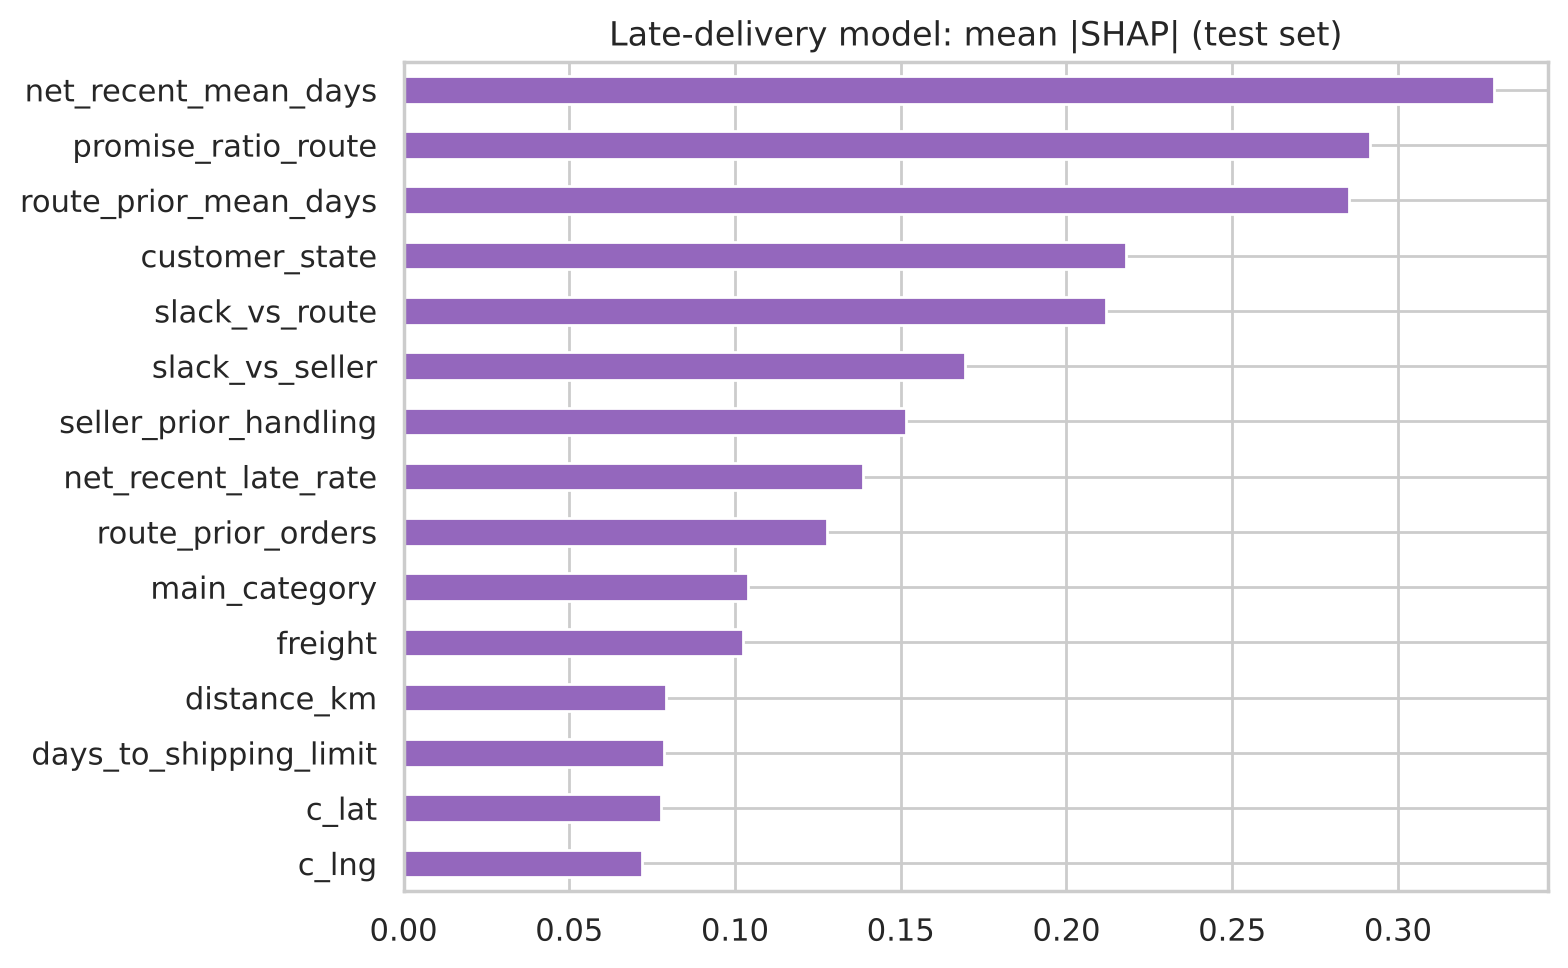

,mean_abs_shap,"spearman(feature, shap)"
customer_state,0.218,NaN
distance_km,0.079,NaN
freight,0.102,NaN
main_category,0.104,NaN
net_recent_late_rate,0.139,0.315
net_recent_mean_days,0.329,0.481
promise_ratio_route,0.292,0.931
route_prior_mean_days,0.285,0.808
route_prior_orders,0.128,-0.538
seller_prior_handling,0.151,NaN


In [27]:
contrib = clf.booster_.predict(Xall[te], pred_contrib=True)
shap_df = pd.DataFrame(contrib[:, :-1], columns=num_feats + cat_feats)
imp = shap_df.abs().mean().sort_values(ascending=False)
RESULTS["late_shap_top"] = imp.head(10).round(4).to_dict()
direction = {c: stats.spearmanr(Xall[te][c].astype(float), shap_df[c]).correlation for c in imp.head(10).index if c in num_feats}
RESULTS["late_shap_direction"] = {k: round(v, 2) for k, v in direction.items()}
fig, ax = plt.subplots(figsize=(8, 5))
imp.head(15)[::-1].plot.barh(ax=ax, color="tab:purple"); ax.set_title("Late-delivery model: mean |SHAP| (test set)")
savefig("fig8_shap_importance")
pd.DataFrame({"mean_abs_shap": imp.head(12), "spearman(feature, shap)": pd.Series(direction)}).round(3)

### 5.4 Robustness and sensitivity analysis
1. **Random vs temporal validation** — random 5-fold CV on the same pre-June data.
2. **Feature ablation** — without seller-history features; without the promise; without demand features.
3. **Rolling-origin evaluation** — refit and test on successive months to see how performance varies over time.
4. **Seed variance** — LightGBM test PR-AUC over 5 seeds.

In [28]:
dev = (tr | va).values
skf = StratifiedKFold(5, shuffle=True, random_state=SEED)
cv_ap = []
for f, (a_, b_) in enumerate(skf.split(Xall[dev], y_late[dev])):
    m_ = lgb.LGBMClassifier(**{**lgb_params, "n_estimators": BEST_IT_CLS})
    m_.fit(Xall[dev].iloc[a_], y_late[dev][a_])
    cv_ap.append(average_precision_score(y_late[dev][b_], m_.predict_proba(Xall[dev].iloc[b_])[:, 1]))
RESULTS["random_cv_pr_auc"] = (round(np.mean(cv_ap), 4), round(np.std(cv_ap), 4))
print("Random 5-fold CV PR-AUC:", np.mean(cv_ap), "+/-", np.std(cv_ap), " vs temporal test:", res_cls.loc["LightGBM (refit train+valid)", "PR_AUC"])

def fit_eval(feats, seed=SEED):
    c_ = lgb.LGBMClassifier(**{**lgb_params, "random_state": seed})
    c_.fit(M.loc[tr, feats], y_late[tr], eval_set=[(M.loc[va, feats], y_late[va])], eval_metric="average_precision",
           callbacks=[lgb.early_stopping(100, verbose=False)])
    r_ = lgb.LGBMRegressor(objective="l1", **{**lgb_params, "random_state": seed})
    r_.fit(M.loc[tr, feats], y_days[tr], eval_set=[(M.loc[va, feats], y_days[va])], callbacks=[lgb.early_stopping(100, verbose=False)])
    return (average_precision_score(y_late[te], c_.predict_proba(M.loc[te, feats])[:, 1]),
            roc_auc_score(y_late[te], c_.predict_proba(M.loc[te, feats])[:, 1]),
            mean_absolute_error(y_days[te], r_.predict(M.loc[te, feats])))

allf = num_feats + cat_feats
seller_h = ["seller_prior_orders", "seller_prior_late_rate", "seller_prior_mean_days", "seller_prior_handling", "slack_vs_seller"]
net_h = ["net_recent_late_rate", "net_recent_mean_days", "slack_vs_network"]
abl = {"All features": allf,
       "– seller history": [f for f in allf if f not in seller_h],
       "– promise-related (promise, shipping limit, slack)": [f for f in allf if f not in ["promised_days_int", "days_to_shipping_limit", "promise_ratio_route"] and not f.startswith("slack")],
       "– network recent conditions": [f for f in allf if f not in net_h],
       "– slack features": [f for f in allf if not f.startswith("slack") and f != "promise_ratio_route"],
       "+ demand & month (first specification)": allf + ["demand_prev7d", "p_month"],
       "– geography (states, coords, distance)": [f for f in allf if f not in ["customer_state", "seller_state", "c_lat", "c_lng", "s_lat", "s_lng", "distance_km", "same_state"]]}
abl_res = pd.DataFrame({k: dict(zip(["PR_AUC", "ROC_AUC", "MAE_days"], fit_eval(v))) for k, v in abl.items()}).T
RESULTS["ablation"] = abl_res.round(4).reset_index().to_dict("records")
abl_res.round(4)

Random 5-fold CV PR-AUC: 0.35066940911591793 +/- 0.013365223375773646  vs temporal test: 0.05716611374788558


,PR_AUC,ROC_AUC,MAE_days
All features,0.0570,0.6554,4.8432
– seller history,0.0515,0.6199,4.9575
"– promise-related (promise, shipping limit, slack)",0.0313,0.4461,4.9798
– network recent conditions,0.0386,0.4845,5.0990
– slack features,0.0460,0.5836,4.7378
+ demand & month (first specification),0.0358,0.4941,5.3618
"– geography (states, coords, distance)",0.0322,0.4273,5.2018


PR-AUC across seeds: [0.0583 0.0583 0.055  0.0511 0.055 ]


late_rate          0.0769
AP_lgbm            0.1881
AP_logit           0.1615
AP_heuristic       0.1418
ROC_lgbm           0.7268
ROC_logit          0.7034
ROC_heuristic      0.6827
MAE_lgbm           4.6361
MAE_route_hist     5.7155
MAE_promise       12.2879
dtype: float64
{'lgbm_beats_heuristic_AP_months': 10, 'logit_beats_heuristic_AP_months': 8, 'lgbm_beats_routehist_MAE_months': 11, 'months': 11}


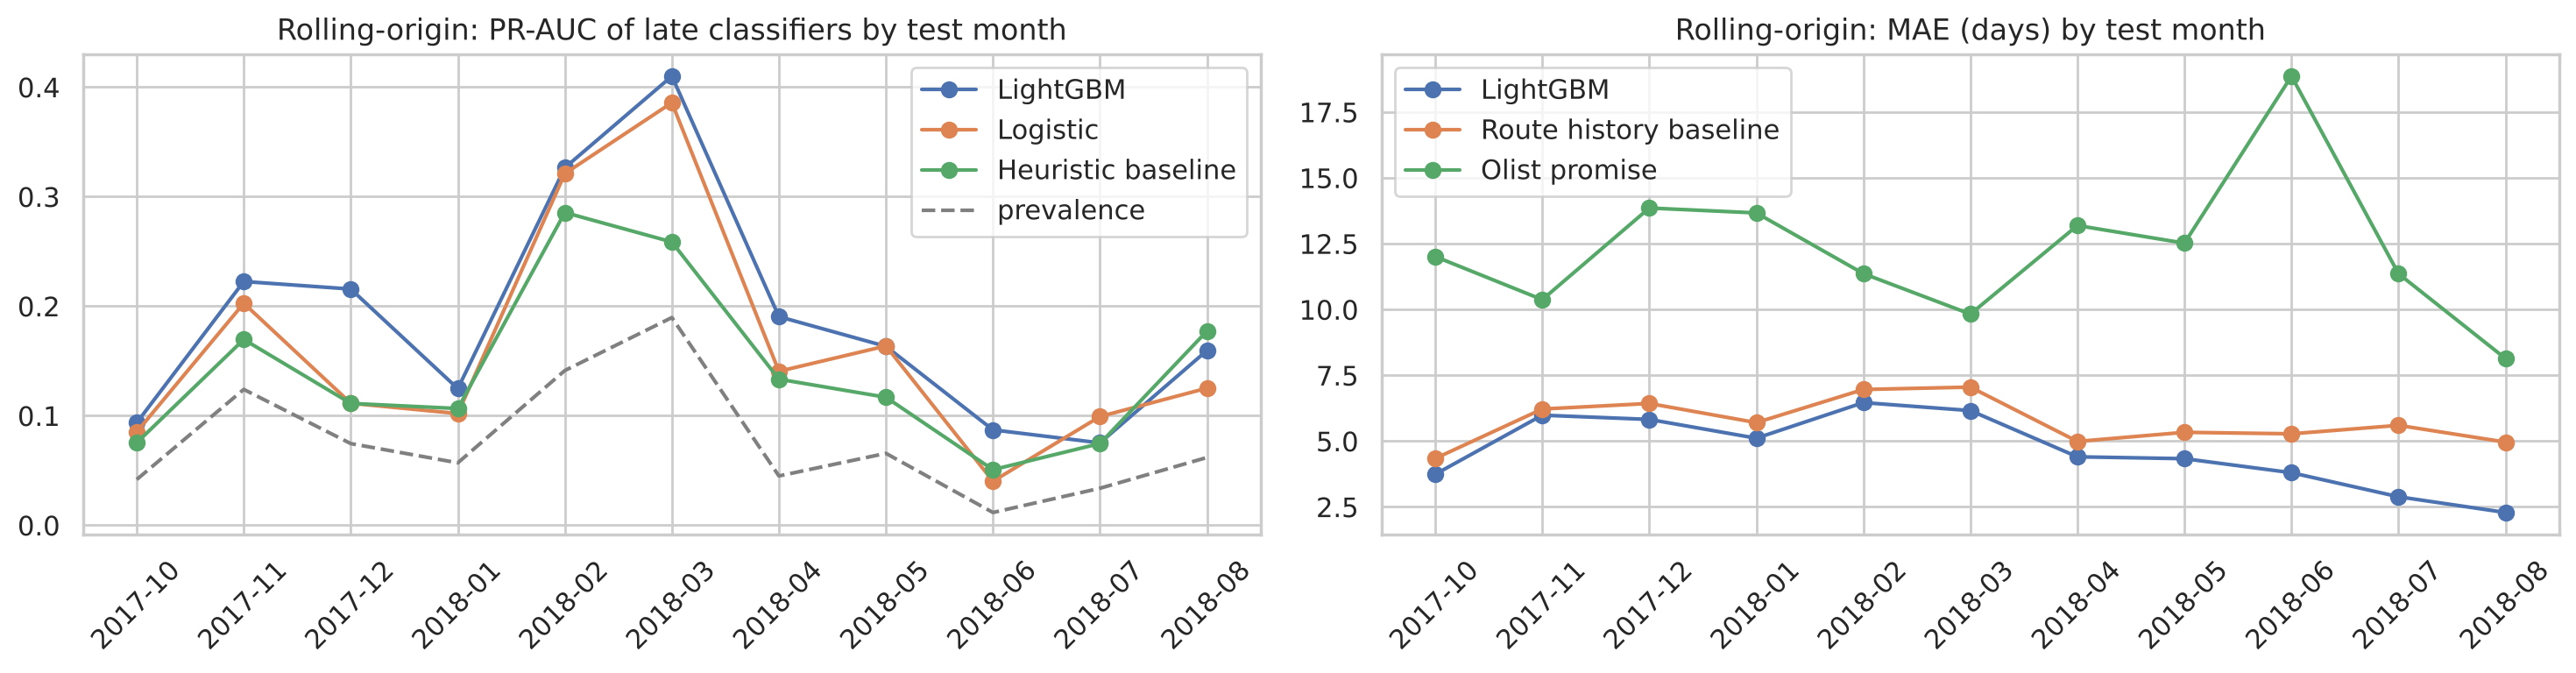

,month,n,late_rate,AP_lgbm,AP_logit,AP_heuristic,ROC_lgbm,ROC_logit,ROC_heuristic,MAE_lgbm,MAE_route_hist,MAE_promise
0,2017-10,4478,0.042,0.094,0.085,0.075,0.707,0.683,0.666,3.742,4.342,12.010
1,2017-11,7288,0.124,0.223,0.203,0.170,0.666,0.662,0.618,5.985,6.219,10.374
2,2017-12,5513,0.075,0.216,0.111,0.111,0.729,0.642,0.628,5.824,6.430,13.855
3,2018-01,7069,0.057,0.125,0.102,0.107,0.703,0.645,0.643,5.111,5.703,13.669
4,2018-02,6555,0.141,0.326,0.321,0.286,0.726,0.721,0.687,6.463,6.961,11.364
5,2018-03,7003,0.190,0.410,0.386,0.259,0.748,0.709,0.624,6.160,7.052,9.825
6,2018-04,6798,0.045,0.190,0.141,0.133,0.800,0.782,0.752,4.404,4.988,13.191
7,2018-05,6749,0.066,0.163,0.164,0.117,0.737,0.737,0.709,4.333,5.335,12.521
8,2018-06,6096,0.012,0.087,0.040,0.051,0.769,0.750,0.769,3.800,5.278,18.864
9,2018-07,6156,0.034,0.075,0.099,0.075,0.652,0.679,0.649,2.886,5.599,11.359


In [29]:
seed_ap = [fit_eval(allf, s)[0] for s in [1, 2, 3, 4, 5]]
RESULTS["seed_pr_auc"] = (round(np.mean(seed_ap), 4), round(np.std(seed_ap), 4))
print("PR-AUC across seeds:", np.round(seed_ap, 4))

roll = []
months = pd.period_range("2017-10", "2018-08", freq="M")
for mth in months:
    trm = (M.purchase_month < mth).values
    tem = (M.purchase_month == mth).values
    if tem.sum() < 200 or y_late[tem].sum() < 10:
        continue
    c_ = lgb.LGBMClassifier(**{**lgb_params, "n_estimators": BEST_IT_CLS}).fit(Xall[trm], y_late[trm])
    r_ = lgb.LGBMRegressor(objective="l1", **{**lgb_params, "n_estimators": reg.best_iteration_ or 300}).fit(Xall[trm], y_days[trm])
    l_ = make_pipeline(pre_lin, LogisticRegression(max_iter=3000, C=0.5)).fit(Xall[trm], y_late[trm])
    pp = c_.predict_proba(Xall[tem])[:, 1]; pl = l_.predict_proba(Xall[tem])[:, 1]; ph = M.promise_ratio_route.values[tem]
    roll.append({"month": str(mth), "n": int(tem.sum()), "late_rate": y_late[tem].mean(),
                 "AP_lgbm": average_precision_score(y_late[tem], pp), "AP_logit": average_precision_score(y_late[tem], pl),
                 "AP_heuristic": average_precision_score(y_late[tem], ph),
                 "ROC_lgbm": roc_auc_score(y_late[tem], pp), "ROC_logit": roc_auc_score(y_late[tem], pl), "ROC_heuristic": roc_auc_score(y_late[tem], ph),
                 "MAE_lgbm": mean_absolute_error(y_days[tem], r_.predict(Xall[tem])),
                 "MAE_route_hist": mean_absolute_error(y_days[tem], M.route_prior_mean_days.values[tem]),
                 "MAE_promise": mean_absolute_error(y_days[tem], M.promised_days.values[tem])})
roll = pd.DataFrame(roll)
roll.to_csv(OUT / "rolling_origin_evaluation.csv", index=False)
RESULTS["rolling"] = roll.round(3).to_dict("records")
roll_mean = roll.drop(columns=["month", "n"]).mean()
wins = {"lgbm_beats_heuristic_AP_months": int((roll.AP_lgbm > roll.AP_heuristic).sum()),
        "logit_beats_heuristic_AP_months": int((roll.AP_logit > roll.AP_heuristic).sum()),
        "lgbm_beats_routehist_MAE_months": int((roll.MAE_lgbm < roll.MAE_route_hist).sum()), "months": len(roll)}
RESULTS["rolling_mean"] = roll_mean.round(4).to_dict(); RESULTS["rolling_wins"] = wins
print(roll_mean.round(4)); print(wins)
fig, ax = plt.subplots(1, 2, figsize=(15, 4))
for c_, l_ in [("AP_lgbm", "LightGBM"), ("AP_logit", "Logistic"), ("AP_heuristic", "Heuristic baseline")]:
    ax[0].plot(roll.month, roll[c_], marker="o", label=l_)
ax[0].plot(roll.month, roll.late_rate, ls="--", c="grey", label="prevalence"); ax[0].legend(); ax[0].tick_params(axis="x", rotation=45)
ax[0].set_title("Rolling-origin: PR-AUC of late classifiers by test month")
for c_, l_ in [("MAE_lgbm", "LightGBM"), ("MAE_route_hist", "Route history baseline"), ("MAE_promise", "Olist promise")]:
    ax[1].plot(roll.month, roll[c_], marker="o", label=l_)
ax[1].legend(); ax[1].tick_params(axis="x", rotation=45); ax[1].set_title("Rolling-origin: MAE (days) by test month")
savefig("fig9_rolling_origin")
roll.round(3)

### 5.5 Operational use of the late-delivery model
At the validation-chosen threshold, what share of late orders would be caught if the top-k% riskiest orders
were proactively managed (e.g. carrier upgrade, proactive customer message)?

In [30]:
cap = []
for nm, sc in [("LightGBM", p_gb_te), ("Logistic", p_lr_te), ("Heuristic", ratio[te].values)]:
    order_ = np.argsort(-sc)
    for k in [0.05, 0.10, 0.20]:
        n = int(k * len(order_)); sel = order_[:n]
        cap.append({"model": nm, "top_share_reviewed": k, "precision": y_late[te][sel].mean(), "recall": y_late[te][sel].sum() / y_late[te].sum(),
                    "lift_vs_random": y_late[te][sel].mean() / y_late[te].mean()})
cap = pd.DataFrame(cap)
RESULTS["late_capture"] = cap.round(3).to_dict("records")
cap.round(3)

,model,top_share_reviewed,precision,recall,lift_vs_random
0,LightGBM,0.05,0.076,0.106,2.113
1,LightGBM,0.10,0.065,0.180,1.801
2,LightGBM,0.20,0.055,0.305,1.526
3,Logistic,0.05,0.100,0.138,2.768
4,Logistic,0.10,0.091,0.253,2.530
5,Logistic,0.20,0.081,0.448,2.240
6,Heuristic,0.05,0.180,0.249,4.971
7,Heuristic,0.10,0.144,0.399,3.989
8,Heuristic,0.20,0.106,0.589,2.947


### 5.6 Conclusions for Task 5
* **Delivery days.** Refit on train+valid, LightGBM (MAE ≈ 3.8 days) and ridge (≈ 3.7) are ~26–28% better than the
  best baseline (training median, 5.2) and ~3.4× better than Olist's own promise (12.7 days, which is deliberately
  conservative). In the rolling evaluation LightGBM beats the route-history baseline in every month.
* **Late delivery.** In the rolling evaluation (1-month horizon) LightGBM has the best average PR-AUC and ROC-AUC and
  beats the heuristic in most months. On the single 3-month block without retraining, however, the heuristic
  (route history ÷ promise) is best and the learned models degrade, especially in Aug 2018: the drivers of lateness
  shift with network-wide disruptions, so a model must be **retrained frequently and monitored against the heuristic**.
* Random K-fold CV overstates PR-AUC several-fold relative to the out-of-time test — a key methodological finding.
* The first specification (with month-of-year and recent demand) failed out of time; this is retained in the ablation
  as evidence of why time-aware features and validation were needed.

## Summary of key results
All numbers quoted in the report are produced by this cell and saved to `outputs/results.json`.

In [31]:
def to_py(o):
    if isinstance(o, dict): return {str(k): to_py(v) for k, v in o.items()}
    if isinstance(o, (list, tuple)): return [to_py(v) for v in o]
    if isinstance(o, (np.integer,)): return int(o)
    if isinstance(o, (np.floating,)): return float(o)
    if isinstance(o, (np.bool_,)): return bool(o)
    if isinstance(o, (pd.Period, pd.Timestamp)): return str(o)
    return o
with open(OUT / "results.json", "w") as fh:
    json.dump(to_py(RESULTS), fh, indent=2, default=str)
print(json.dumps(to_py(RESULTS), indent=1, default=str)[:6000])

{
 "integrity": {
  "orders_without_items": 775,
  "orders_without_payment": 1,
  "orders_with_multiple_reviews": 551,
  "delivered_but_no_delivery_date": 8,
  "carrier_pickup_before_approval": 1359,
  "customer_delivery_before_carrier_pickup": 23,
  "products_missing_category": 610,
  "categories_without_translation": [
   "pc_gamer",
   "portateis_cozinha_e_preparadores_de_alimentos"
  ],
  "customer_ids": 99441,
  "unique_customers": 96096,
  "payment_vs_items_mismatch_gt_R$1": 249
 },
 "delivered_orders_modelling_window": 96203,
 "late_rate_overall": 0.0679,
 "delivery_days_median": 10.21,
 "delivery_days_mean": 12.54,
 "promised_days_median": 23.22,
 "review_ontime_vs_late": {
  "0.0": 4.29,
  "1.0": 2.27
 },
 "late_by_month_max": [
  "2018-03",
  0.19
 ],
 "late_by_state_top": [
  {
   "customer_state": "AL",
   "late_rate": 0.215,
   "n": 396,
   "median_days": 22.329
  },
  {
   "customer_state": "MA",
   "late_rate": 0.175,
   "n": 713,
   "median_days": 19.183
  },
  {
   "cu

## References
[1] Olist and A. Sionek, "Brazilian E-Commerce Public Dataset by Olist," Kaggle, 2018. https://www.kaggle.com/datasets/olistbr/brazilian-ecommerce

[2] R. Agrawal and R. Srikant, "Fast algorithms for mining association rules," Proc. 20th VLDB, 1994, pp. 487–499.

[3] S. Brin, R. Motwani, J. D. Ullman, and S. Tsur, "Dynamic itemset counting and implication rules for market basket data," Proc. ACM SIGMOD, 1997, pp. 255–264.

[4] J. MacQueen, "Some methods for classification and analysis of multivariate observations," Proc. 5th Berkeley Symp., 1967, pp. 281–297.

[5] P. J. Rousseeuw, "Silhouettes: a graphical aid to the interpretation and validation of cluster analysis," J. Comput. Appl. Math., vol. 20, pp. 53–65, 1987.

[6] L. Hubert and P. Arabie, "Comparing partitions," J. Classification, vol. 2, no. 1, pp. 193–218, 1985.

[7] F. T. Liu, K. M. Ting, and Z.-H. Zhou, "Isolation forest," Proc. IEEE ICDM, 2008, pp. 413–422.

[8] M. M. Breunig, H.-P. Kriegel, R. T. Ng, and J. Sander, "LOF: identifying density-based local outliers," Proc. ACM SIGMOD, 2000, pp. 93–104.

[9] G. Ke et al., "LightGBM: a highly efficient gradient boosting decision tree," Adv. NeurIPS, vol. 30, 2017.

[10] T. Saito and M. Rehmsmeier, "The precision-recall plot is more informative than the ROC plot when evaluating binary classifiers on imbalanced datasets," PLoS ONE, vol. 10, no. 3, e0118432, 2015.

[11] S. M. Lundberg and S.-I. Lee, "A unified approach to interpreting model predictions," Adv. NeurIPS, vol. 30, 2017.

[12] Y. Romano, E. Patterson, and E. Candès, "Conformalized quantile regression," Adv. NeurIPS, vol. 32, 2019.